# Quantile surrogate for the DIII-D TGLF database

Same pipeline as `tglf_uncertainty.ipynb`, but the data are the DIII-D TGLF runs of two teams: `data/team_a_d3d_database.csv` and `data/team_b_d3d_database.csv`, combined into one table.

**Contents**

1. Setup
2. Data: loading, splitting and preprocessing
3. Model: quantile network ensembles
4. Training
5. Learning curves: how much training data is needed?
6. Band, width and spread against the input parameters
7. Held-out profile
8. Are the held-out inputs like the training inputs?
9. Retraining on the new database (`d3d_mydb_101`)

## 1. Setup

Imports, plotting style and the constants shared by every section.

In [198]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
from pathlib import Path


In [199]:
# plotting style, shared by every figure
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.fontsize": 8, "figure.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})

# the three targets, in the column order used everywhere (see step 2.1)
TARGET_KEYS = ["Q_i", "Q_e", "Gamma_e"]
TARGET_NAMES = ["Ion heat flux Q_i", "Electron heat flux Q_e", "Electron particle flux Gamma_e"]
TARGET_COLORS = ["tab:blue", "tab:orange", "tab:green"]
TARGET_MARKERS = ["o", "s", "^"]
LOG_FLUX_AXIS = [True, True, False]    # heat fluxes are positive and span orders of magnitude; the particle flux can be zero or negative

# analysis settings
N_FLUX_BINS = 50       # equal-width log10 flux bins for the training-data analysis (Figure 6)
MIN_CASES_PER_BIN = 3  # bins with fewer evaluation cases than this are not shown
N_INPUT_BINS = 10      # equal-count bins of each input for Figure 7

# figure titles: "Figure 2a. <text> (validation set)"; a = validation set, b = test set
SPLIT_LETTER = {"validation": "a", "test": "b"}

def fig_title(number, text, split=None, note=None):
    if split is None:
        return f"Figure {number}. {text}"
    return f"Figure {number}{SPLIT_LETTER[split]}. {text} ({split} set" + (f"; {note})" if note else ")")

## 2. Data: loading, splitting and preprocessing

The two team databases are stacked into one table (`data/team_a_d3d_database.csv`, `data/team_b_d3d_database.csv`). Each row is one TGLF run, with every input and the fluxes.
Preprocessing follows `tglf_uncertainty.ipynb`; every statistic (correlations, variances, scalers) comes from the training set only.

0. Harmonize the two schemas: team A names the species `_1` (electron) and `_2` (ion), team B uses `_e` and `_i`. Keep only the columns both teams have.
1. Split into training, validation and test sets (70 / 15 / 15) **by base case**. Several runs share a `case` id (the same plasma with perturbed inputs), so a random row split would put near-copies of a run in both train and test.
2. Drop the fluxes from the inputs and keep three as targets: $Q_i$, $Q_e$ and $\Gamma_e$. Drop the bookkeeping columns and the perturbation factors `f_*` (not TGLF inputs).
3. Encode what is left (all columns are numeric here).
4. Drop invalid rows (non-finite values or a heat flux $\le 0$), highly correlated features (|r| > 0.9) and low-variance features.
5. Standardize the inputs.
6. Take the natural log of the two heat fluxes; $\Gamma_e$ can be negative and stays as it is.


In [200]:
# step 1: load both team databases, put them on one schema, and find the flux columns

DATA_DIR = Path("data") if Path("data").exists() else Path("../data")   # works from the repo root or from notebooks/

# team A is our team: its frozen database is Ryan's notebooks/ryan/task4/d3d_team_database.csv (read in place, not copied)
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebooks" / "ryan").is_dir())
df_a = pd.read_csv(REPO / "notebooks" / "ryan" / "task4" / "d3d_team_database.csv")
df_b = pd.read_csv(DATA_DIR / "team_b_d3d_database.csv")

# team A: species 1 / 2 -> e / i, the naming team B uses (ZS_1 -> ZS_e, RLTS_2 -> RLTS_i, ...)
df_a = df_a.rename(columns=lambda c: c[:-2] + "_e" if c.endswith("_1") else c[:-2] + "_i" if c.endswith("_2") else c)
df_a["team"], df_b["team"] = "A", "B"

# keep the columns both teams have (drops team-specific extras such as Gamma_i, SHEAR, positive_heat_fluxes and A's constant TGLF switches)
common_cols = [c for c in df_a.columns if c in df_b.columns]
df = pd.concat([df_a[common_cols], df_b[common_cols]], ignore_index=True)
print(f"team A: {len(df_a)} rows, team B: {len(df_b)} rows -> combined: {df.shape}")

FLUX_COLS = ["Q_i", "Q_e", "Gamma_e"]   # the three output fluxes present in both teams' files
y_variables = [c for c in FLUX_COLS if c in df.columns]
assert y_variables == FLUX_COLS


team A: 3884 rows, team B: 3500 rows -> combined: (7384, 37)


In [201]:
# step 2: preprocess the data
# order matters: encode -> drop invalid rows -> drop correlated -> drop low variance (both on unscaled data) -> scale last, so the variance filter is meaningful

# step 2.0: train, validation, and test split -> 70, 15, 15 split, grouped by base case
# rows that share a `case` id are perturbed copies of one plasma, so whole cases go to one set (no leakage between train and test)

cases = np.asarray(df["case"].unique(), dtype=object)
train_val_cases, test_cases = train_test_split(cases, test_size=0.15, random_state=RANDOM_STATE, shuffle=True)
train_cases, val_cases = train_test_split(train_val_cases, test_size=0.1765, random_state=RANDOM_STATE, shuffle=True)  # 0.1765 * 0.85 ≈ 0.15
train_df, val_df, test_df = [df[df["case"].isin(s)] for s in (train_cases, val_cases, test_cases)]
print({n: len(d) for n, d in (("train", train_df), ("val", val_df), ("test", test_df))})

# step 2.1: remove output columns from the input dataframes for preprocessing (we don't want to use the outputs as inputs for the model)

ALL_FLUX_COLS = y_variables                              # the three fluxes; none of them may be an input
OUTPUT_COLS = ["Q_i", "Q_e", "Gamma_e"]                  # the three targets: Q_i, Q_e, Gamma_e
train_X_df, val_X_df, test_X_df = [df.drop(columns=ALL_FLUX_COLS) for df in (train_df, val_df, test_df)]
train_y_df, val_y_df, test_y_df = [df[OUTPUT_COLS] for df in (train_df, val_df, test_df)]

# step 2.2: categorical variable encoding (nothing is categorical after the drop, so this only removes META_COLS)

# not TGLF inputs: ids / provenance, and the f_* factors used to perturb each base case (the perturbed inputs themselves are kept)
META_COLS = ("case_id", "case", "contributor", "member", "seed", "source_file", "team", "radius",
             "varied_inputs_source", "fixed_inputs_source", "f_Te", "f_Ti", "f_n", "f_tau", "f_nu")

def encode_categoricals(df, drop_cols=META_COLS):  # bookkeeping columns and the perturbation factors f_*
    """Drop the non-informative columns, convert boolean (True / False) columns to numeric (1 / 0),
    then one-hot encode (drop='first') the remaining object columns.
    Returns the new dataframe (categorical columns replaced by their encoded versions) and the fitted encoder (None if nothing to encode).
    Does not modify the input dataframe, and is a no-op on a dataframe that has no categorical columns left."""
    df = df.drop(columns=list(drop_cols), errors='ignore') # drop non-informative categorical features
    df = df.astype({c: int for c in df.select_dtypes(include='bool').columns}) # boolean -> numeric, since numpy cannot subtract booleans (needed by the variance step)
    categorical_features = df.select_dtypes(include=['object']).columns.tolist() # compute AFTER the drop
    if not categorical_features:
        return df, None
    onehot_encoder = OneHotEncoder(drop='first', sparse_output=False)
    df_encoded = pd.DataFrame(
        onehot_encoder.fit_transform(df[categorical_features]),
        columns=onehot_encoder.get_feature_names_out(categorical_features),
        index=df.index,
    )
    return pd.concat([df.drop(columns=categorical_features), df_encoded], axis=1), onehot_encoder # replace the original categorical columns with their encoded versions

train_X_df, val_X_df, test_X_df = [encode_categoricals(df)[0] for df in (train_X_df, val_X_df, test_X_df)]  # encode categoricals in all splits

# step 2.3: remove invalid rows (not statistical outliers: large fluxes are real physics, so those stay)
# a row is invalid if any value is NaN / infinite or a heat flux is <= 0 (unphysical, and log(energy_flux) is undefined).
# the rule uses no training statistics, so it is applied to every split without leaking anything; X and y are filtered together to stay aligned

ENERGY_COLS = ["Q_i", "Q_e"]   # the heat fluxes

def valid_rows(X, y):
    return np.isfinite(X.select_dtypes("number")).all(axis=1) & np.isfinite(y).all(axis=1) & (y[ENERGY_COLS] > 0).all(axis=1)

for name, X, y in (("train", train_X_df, train_y_df), ("val", val_X_df, val_y_df), ("test", test_X_df, test_y_df)):
    print(f"{name}: dropping {(~valid_rows(X, y)).sum()} invalid rows of {len(X)}")
train_mask, val_mask, test_mask = valid_rows(train_X_df, train_y_df), valid_rows(val_X_df, val_y_df), valid_rows(test_X_df, test_y_df)
train_X_df, train_y_df = train_X_df[train_mask], train_y_df[train_mask]
val_X_df, val_y_df = val_X_df[val_mask], val_y_df[val_mask]
test_X_df, test_y_df = test_X_df[test_mask], test_y_df[test_mask]

# step 2.4: remove highly correlated features (correlation does not depend on scaling, so this runs on the raw values; statistics come from the training set only)

corr_matrix = train_X_df.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_features = [column for column in upper_tri.columns if any(upper_tri[column] > 0.9)]  # threshold for high correlation
high_corr_features_df = pd.DataFrame({
    'feature1': high_corr_features,
    'feature2': [upper_tri[column].idxmax() for column in high_corr_features],
    'max_correlation': [upper_tri[column].max() for column in high_corr_features]
})
high_corr_features_df.sort_values(by='max_correlation', ascending=False, inplace=True)
train_X_df, val_X_df, test_X_df = [df.drop(columns=high_corr_features) for df in (train_X_df, val_X_df, test_X_df)]  # same columns dropped from every split

# step 2.5: remove low variance features
# raw variance depends on each feature's units, so compare features on a common footing: variance after min-max scaling to [0, 1] (training set)

feature_range = train_X_df.max() - train_X_df.min()
minmax_variance = ((train_X_df - train_X_df.min()) / feature_range.replace(0, np.nan)).var().fillna(0)  # constant columns (range 0) get variance 0
low_variance_features = minmax_variance.index[minmax_variance < 0.01].tolist()  # threshold for low variance
low_variance_features_df = pd.DataFrame({'feature': low_variance_features, 'variance': minmax_variance[low_variance_features]})
low_variance_features_df.sort_values(by='variance', ascending=True, inplace=True)
train_X_df, val_X_df, test_X_df = [df.drop(columns=low_variance_features) for df in (train_X_df, val_X_df, test_X_df)]  # same columns dropped from every split

# step 2.6: feature scaling via standardization (last, so it cannot hide differences in variance from step 2.5)

def scale_features(train_X_df, val_X_df, test_X_df):
    """Standardize the continuous features (zero mean, unit variance) using the training set statistics.
    One-hot (0/1) columns are left as they are. Returns the three scaled dataframes and the fitted scaler."""
    binary_cols = [c for c in train_X_df.columns if set(train_X_df[c].unique()) <= {0, 1}]
    continuous_cols = [c for c in train_X_df.columns if c not in binary_cols]
    scaler = StandardScaler().fit(train_X_df[continuous_cols])
    scaled = []
    for df in (train_X_df, val_X_df, test_X_df):
        df = df.copy()
        df[continuous_cols] = scaler.transform(df[continuous_cols])
        scaled.append(df)
    return (*scaled, scaler)

train_X_scaled, val_X_scaled, test_X_scaled, scaler = scale_features(train_X_df, val_X_df, test_X_df)

# step 2.7: log targets, so models can be trained on both the raw fluxes and log(energy_flux)
# only the heat fluxes are always positive (checked in step 2.3), so only those get a log; particle flux can be negative and stays raw
# predictions from a log model are converted back with np.exp(pred) to compare with the raw-target models

def log_targets(y_df):
    y_log = y_df.copy()
    y_log[ENERGY_COLS] = np.log(y_df[ENERGY_COLS])   # natural log
    return y_log.rename(columns={c: f"log_{c}" for c in ENERGY_COLS})

train_y_log_df, val_y_log_df, test_y_log_df = [log_targets(y) for y in (train_y_df, val_y_df, test_y_df)]
# raw targets: train_y_df / val_y_df / test_y_df;  log targets: train_y_log_df / val_y_log_df / test_y_log_df

{'train': 5058, 'val': 1102, 'test': 1224}
train: dropping 36 invalid rows of 5058
val: dropping 8 invalid rows of 1102
test: dropping 9 invalid rows of 1224


## 3. Model: quantile network ensembles

Three architectures are compared. All map the scaled inputs from step 2 to **3 targets × 3 quantiles** (5th, 50th and 95th percentile of $\log Q_i$, $\log Q_e$ and $\Gamma_e$). The middle quantile is the prediction and the outer two form the 90% interval.

- **`TGLFNN`**: two hidden layers of 64 units (GELU), then an 8-unit ReLU bottleneck, then the 9 outputs. `TGLFNNEnsemble` averages each quantile over its members.
- **`TGLFNNMinimalHidden`**: a single hidden layer of 60 ReLU units, then the 9 outputs. `TGLFNNMinimalHiddenEnsemble` averages over its members.

- **`TGLFLinear`**: no hidden layer, a single linear map from the inputs to the 9 outputs. This is the baseline (linear quantile regression). `TGLFLinearEnsemble` averages over its members.

Members of an ensemble differ only in their random seed.

**Loss.** The pinball loss: for quantile $q$ and error $e = y - \hat{y}$ it is $\max(q\,e,\ (q-1)\,e)$. Under-predicting costs $q$ and over-predicting costs $1-q$, so each output settles at the value that a fraction $q$ of the data falls below.
The raw quantiles can cross, so `sorted_quantiles` sorts them before use.

**Input size.** `INPUT_DIM` is read from `train_X_scaled`, so the networks follow whatever features survive step 2.


In [202]:
QUANTILES = (0.05, 0.50, 0.95)   # low, medium, high
INPUT_DIM = train_X_scaled.shape[1]   # number of features left after step 2
N_TARGETS = 3                    # Q_i, Q_e, Gamma_e (heat fluxes in log space, see step 2)

class TGLFNN(nn.Module):
    """One member: INPUT_DIM -> 64 -> 64 -> 8 -> (3 targets x 3 quantiles), shape (batch, target, quantile)."""
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=64, latent_dim=8, n_targets=N_TARGETS, n_quantiles=len(QUANTILES)):
        super().__init__()
        self.n_targets, self.n_quantiles = n_targets, n_quantiles
        self.hidden1 = nn.Linear(input_dim, hidden_dim)
        self.hidden2 = nn.Linear(hidden_dim, hidden_dim)
        self.bottleneck = nn.Linear(hidden_dim, latent_dim)
        self.output = nn.Linear(latent_dim, n_targets * n_quantiles)

    def forward(self, x):
        x = F.gelu(self.hidden1(x))
        x = F.gelu(self.hidden2(x))
        x = F.relu(self.bottleneck(x))
        return self.output(x).view(-1, self.n_targets, self.n_quantiles)

class TGLFNNEnsemble(nn.Module):
    def __init__(self, num_models=5, seeds=(42, 43, 44, 45, 46), **kw):
        super().__init__()
        assert len(seeds) == num_models, "Number of seeds must match number of models"
        models = []
        for seed in seeds:
            torch.manual_seed(seed)
            models.append(TGLFNN(**kw))
        self.models = nn.ModuleList(models)

    def member_outputs(self, x):
        return torch.stack([m(x) for m in self.models])   # (member, batch, target, quantile)

    def forward(self, x):
        return self.member_outputs(x).mean(dim=0)         # average each quantile across members
    
class TGLFNNMinimalHidden(nn.Module):
    """One member: INPUT_DIM -> 60 -> (3 targets x 3 quantiles), shape (batch, target, quantile)."""
    def __init__(self, input_dim=INPUT_DIM, hidden_dim=60, n_targets=N_TARGETS, n_quantiles=len(QUANTILES)):
        super().__init__()
        self.n_targets, self.n_quantiles = n_targets, n_quantiles
        self.hidden = nn.Linear(input_dim, hidden_dim)
        self.output = nn.Linear(hidden_dim, n_targets * n_quantiles)

    def forward(self, x):
        x = F.relu(self.hidden(x))
        return self.output(x).view(-1, self.n_targets, self.n_quantiles)

class TGLFNNMinimalHiddenEnsemble(nn.Module):
    def __init__(self, num_models=32, seeds=(42, 43, 44, 45, 46), **kw):
        super().__init__()
        assert len(seeds) == num_models, "Number of seeds must match number of models"
        models = []
        for seed in seeds:
            torch.manual_seed(seed)
            models.append(TGLFNNMinimalHidden(**kw))
        self.models = nn.ModuleList(models)

    def member_outputs(self, x):
        return torch.stack([m(x) for m in self.models])   # (member, batch, target, quantile)

    def forward(self, x):
        return self.member_outputs(x).mean(dim=0)         # average each quantile across members

class TGLFLinear(nn.Module):
    """Baseline, one member: INPUT_DIM -> (3 targets x 3 quantiles), shape (batch, target, quantile). Linear quantile regression."""
    def __init__(self, input_dim=INPUT_DIM, n_targets=N_TARGETS, n_quantiles=len(QUANTILES)):
        super().__init__()
        self.n_targets, self.n_quantiles = n_targets, n_quantiles
        self.output = nn.Linear(input_dim, n_targets * n_quantiles)

    def forward(self, x):
        return self.output(x).view(-1, self.n_targets, self.n_quantiles)

class TGLFLinearEnsemble(nn.Module):
    def __init__(self, num_models=5, seeds=(42, 43, 44, 45, 46), **kw):
        super().__init__()
        assert len(seeds) == num_models, "Number of seeds must match number of models"
        models = []
        for seed in seeds:
            torch.manual_seed(seed)
            models.append(TGLFLinear(**kw))
        self.models = nn.ModuleList(models)

    def member_outputs(self, x):
        return torch.stack([m(x) for m in self.models])   # (member, batch, target, quantile)

    def forward(self, x):
        return self.member_outputs(x).mean(dim=0)         # average each quantile across members

def pinball_loss(pred, y, quantiles=QUANTILES):
    """Quantile (pinball) loss. pred: (batch, target, quantile); y: (batch, target), both standardized."""
    q = torch.as_tensor(quantiles, dtype=pred.dtype, device=pred.device)
    err = y.unsqueeze(-1) - pred                          # positive when the prediction is too low
    return torch.maximum(q * err, (q - 1) * err).mean()

def range_of_quantiles(pred):
    """Compute the range (high - low) of the quantile axis."""
    return pred[..., -1] - pred[..., 0]

def sorted_quantiles(pred):
    """Sort the quantile axis so low <= medium <= high (the raw outputs can cross)."""
    return torch.sort(pred, dim=-1).values

## 4. Training

Each member is trained on the standardized training targets (log heat fluxes, raw $\Gamma_e$) with the full training set in every step (no minibatches), using Adam: a warmup phase at `WARMUP_LR`, then `LR` for the rest of `EPOCHS`. The validation and test sets play no part in training.

`SEEDS_PAPER` draws 32 random seeds; the first five (`SEEDS`) are used here. `y_mean` and `y_std` come from the training set only, and `predict_ensemble` uses them to convert outputs back to flux units. It returns the interval `bands` with shape (cases, 3 targets, 3 quantiles), the member-to-member `spread` of the median and the interval `width`.

In [203]:
import random

EPOCHS, WARMUP_EPOCHS = 150, 30
WARMUP_LR, LR = 0.001, 0.003

random.seed(RANDOM_STATE)   # same seeds on every run
SEEDS_PAPER = random.sample(range(1000), 32)
SEEDS = SEEDS_PAPER[:5]

y_mean = train_y_log_df.values.mean(axis=0)
y_std = train_y_log_df.values.std(axis=0)

def to_tensor(e):
    return torch.as_tensor(np.asarray(e), dtype=torch.float32)

X_train_t = to_tensor(train_X_scaled.values)
y_train_t = to_tensor((train_y_log_df.values - y_mean) / y_std)

def fit_member(member_cls, seed, warmup_lr=WARMUP_LR, lr=LR, X_train=X_train_t, y_train=y_train_t):
    """Train one network of type member_cls (e.g. TGLFNN). Returns the model, the loss per epoch and the mean interval width per epoch."""
    epoch_losses, epoch_widths = [], []
    torch.manual_seed(seed)
    model = member_cls()
    warmup_optimizer = torch.optim.Adam(model.parameters(), lr=warmup_lr)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(EPOCHS):
        model.train()
        opt = warmup_optimizer if epoch < WARMUP_EPOCHS else optimizer
        opt.zero_grad()
        out = model(X_train)
        loss = pinball_loss(out, y_train)
        epoch_losses.append(loss.item())
        epoch_widths.append(range_of_quantiles(sorted_quantiles(out.detach())).mean().item())
        loss.backward()
        opt.step()
    return model, epoch_losses, epoch_widths

def fit_ensemble(member_cls=TGLFNN, ensemble_cls=TGLFNNEnsemble, seeds=SEEDS, **kw):
    results = [fit_member(member_cls, seed, **kw) for seed in seeds]
    ensemble = ensemble_cls(num_models=len(seeds), seeds=seeds)
    ensemble.models = nn.ModuleList([r[0] for r in results])
    return ensemble, [r[1] for r in results], [r[2] for r in results]

def predict_ensemble(ensemble, X):
    """X: scaled feature dataframe. Returns
    bands: (cases, 3 targets, 3 quantiles) in flux units (lower, median, upper),
    spread: member-to-member standard deviation of the median, in the model's target units (log for the heat fluxes),
    width: upper - lower in flux units, (cases, 3 targets)."""
    ensemble.eval()
    with torch.no_grad():
        members = sorted_quantiles(ensemble.member_outputs(to_tensor(X.values))).numpy()   # (member, case, target, quantile), standardized
    members = members * y_std.reshape(1, 1, 3, 1) + y_mean.reshape(1, 1, 3, 1)             # back to the log / raw target scale
    spread = members[..., 1].std(axis=0)
    bands = members.mean(axis=0)
    bands[:, :2, :] = np.exp(bands[:, :2, :])                                              # heat fluxes: undo the natural log
    return bands, spread, bands[..., 2] - bands[..., 0]

Fit all three ensembles on the same training data and seeds.

In [204]:
tglfnn_ensemble, tglfnn_epoch_losses, tglfnn_epoch_widths = fit_ensemble(TGLFNN, TGLFNNEnsemble)
minimal_ensemble, minimal_epoch_losses, minimal_epoch_widths = fit_ensemble(TGLFNNMinimalHidden, TGLFNNMinimalHiddenEnsemble)
linear_ensemble, linear_epoch_losses, linear_epoch_widths = fit_ensemble(TGLFLinear, TGLFLinearEnsemble)

**Figure 1.** Training curves for all three ensembles (`TGLFNN`, minimal, linear baseline): pinball loss and mean interval width per epoch. Each boxed row is one model; columns are the two curves. A curve that is still falling at the last epoch means more training would help.

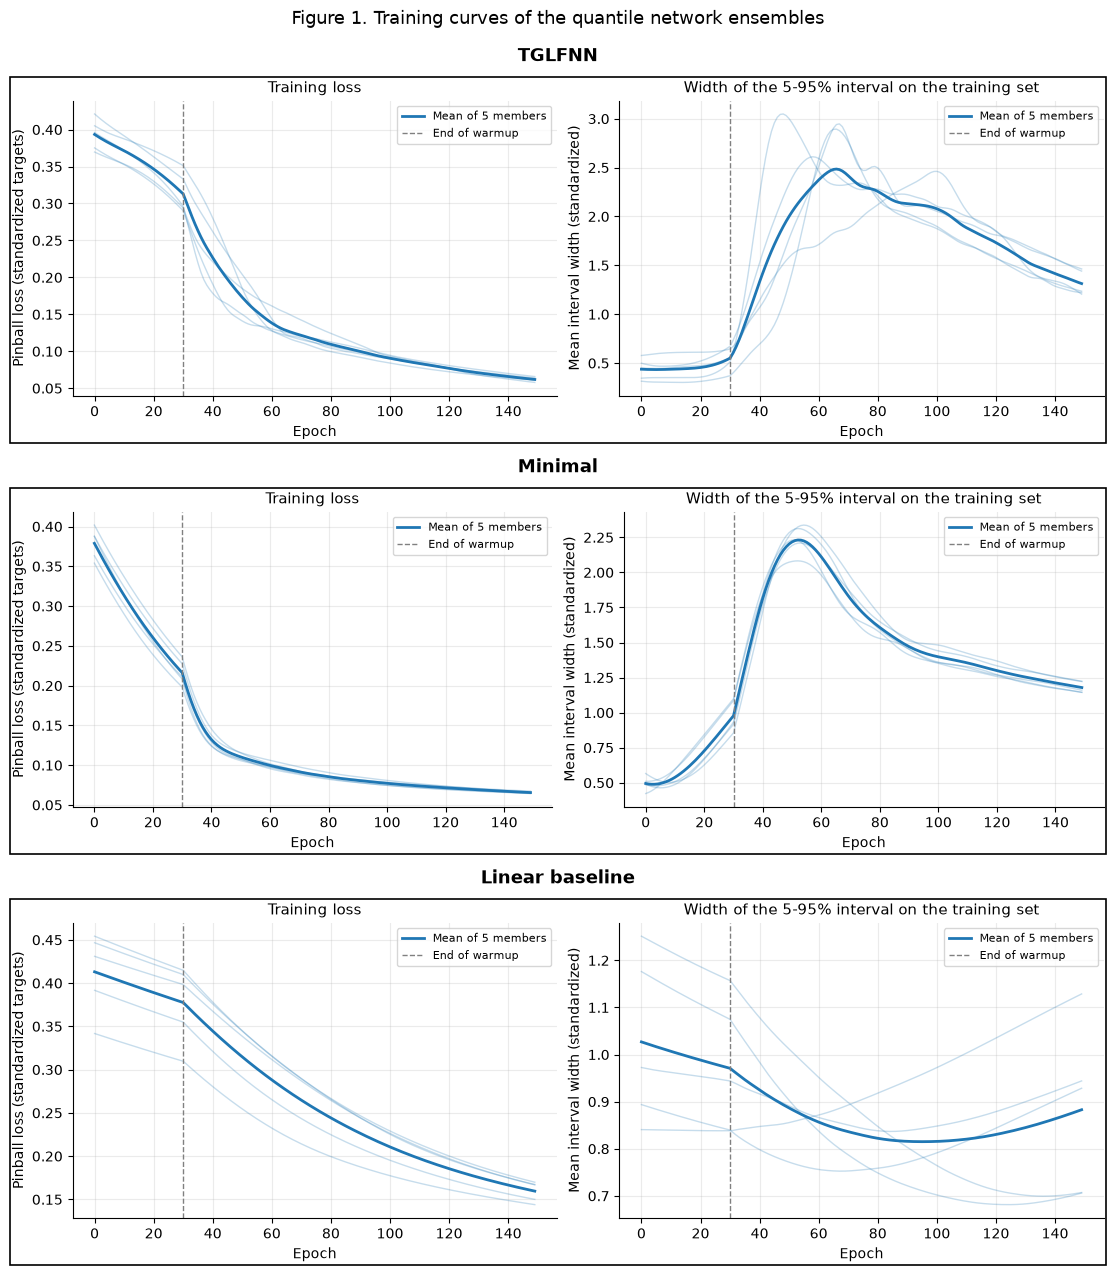

In [205]:
# Figure 1: training curves, one boxed row per model (same layout as the parity plots). One faint line per member, the bold line is the mean over the five members.
CURVE_MODELS = [
    ("TGLFNN", tglfnn_epoch_losses, tglfnn_epoch_widths),
    ("Minimal", minimal_epoch_losses, minimal_epoch_widths),
    ("Linear baseline", linear_epoch_losses, linear_epoch_widths),
]
CURVE_PANELS = [   # (index into a CURVE_MODELS entry, y label, title)
    (1, "Pinball loss (standardized targets)", "Training loss"),
    (2, "Mean interval width (standardized)", "Width of the 5-95% interval on the training set"),
]

fig = plt.figure(figsize=(11, 4.2 * len(CURVE_MODELS)), constrained_layout=True)
strips = fig.subfigures(2 * len(CURVE_MODELS), 1, height_ratios=[0.12, 1] * len(CURVE_MODELS), hspace=0.0)   # title strip, boxed row, title strip, ...
for r, entry in enumerate(CURVE_MODELS):
    title_strip, row_fig = strips[2 * r], strips[2 * r + 1]
    title_strip.text(0.5, 0.25, entry[0], ha="center", va="bottom", fontsize=13, fontweight="bold")
    row_fig.add_artist(plt.Rectangle((0.002, 0.002), 0.996, 0.996, transform=row_fig.transSubfigure, fill=False, edgecolor="black", linewidth=1.2))
    for ax, (idx, ylabel, title) in zip(row_fig.subplots(1, 2), CURVE_PANELS):
        per_member = entry[idx]
        for curve in per_member:
            ax.plot(curve, color="tab:blue", alpha=0.25, linewidth=1)
        ax.plot(np.mean(per_member, axis=0), color="tab:blue", linewidth=2, label=f"Mean of {len(per_member)} members")
        ax.axvline(WARMUP_EPOCHS, color="gray", linestyle="--", linewidth=1, label="End of warmup")
        ax.set(xlabel="Epoch", ylabel=ylabel, title=title)
        ax.legend()
fig.suptitle(fig_title(1, "Training curves of the quantile network ensembles"))
plt.show()


In [206]:
SPLITS = {}
for name, X_scaled, X_raw, y_raw in [("validation", val_X_scaled, val_X_df, val_y_df), ("test", test_X_scaled, test_X_df, test_y_df)]:
    tglfnn_bands, tglfnn_spread, tglfnn_width = predict_ensemble(tglfnn_ensemble, X_scaled)
    minimal_bands, minimal_spread, minimal_width = predict_ensemble(minimal_ensemble, X_scaled)
    SPLITS[f"tglfnn_{name}"] = {"bands": tglfnn_bands, "spread": tglfnn_spread, "width": tglfnn_width, "y_true": y_raw.values, "X": X_raw}     # y_true in flux units, same column order as the bands
    linear_bands, linear_spread, linear_width = predict_ensemble(linear_ensemble, X_scaled)
    SPLITS[f"minimal_{name}"] = {"bands": minimal_bands, "spread": minimal_spread, "width": minimal_width, "y_true": y_raw.values, "X": X_raw}     # y_true in flux units, same column order as the bands
    SPLITS[f"linear_{name}"] = {"bands": linear_bands, "spread": linear_spread, "width": linear_width, "y_true": y_raw.values, "X": X_raw}

train_sd = train_y_df.std().to_numpy()

def evaluate(split):
    bands, y = SPLITS[split]["bands"], SPLITS[split]["y_true"]
    rows = []
    for t, key in enumerate(TARGET_KEYS):
        median, true = bands[:, t, 1], y[:, t]
        sse = np.sum((median - true) ** 2)
        rows.append({
            "split": split, "target": key,
            "R2 (median)": 1 - sse / np.sum((true - true.mean()) ** 2),
            "nRMSE (median)": np.sqrt(sse / len(true)) / train_sd[t],
            "spread (median)": SPLITS[split]["spread"][:, t].mean() / train_sd[t],
            "width (median)": SPLITS[split]["width"][:, t].mean() / train_sd[t],
            "coverage (5-95%)": np.mean((true >= bands[:, t, 0]) & (true <= bands[:, t, 2])),
        })
    return pd.DataFrame(rows)

print("Table 1. Accuracy of the median prediction and coverage of the 5-95% interval (nominal coverage 0.90)")
table_1 = pd.concat([evaluate(split) for split in SPLITS], ignore_index=True).round(3)
table_1


Table 1. Accuracy of the median prediction and coverage of the 5-95% interval (nominal coverage 0.90)


,split,target,R2 (median),nRMSE (median),spread (median),width (median),coverage (5-95%)
0,tglfnn_validation,Q_i,0.954,0.224,0.007,1.230,0.958
1,tglfnn_validation,Q_e,0.753,0.518,0.002,1.103,0.964
2,tglfnn_validation,Gamma_e,0.843,0.408,0.096,1.405,0.966
3,minimal_validation,Q_i,0.936,0.266,0.005,0.915,0.922
4,minimal_validation,Q_e,0.633,0.632,0.002,0.767,0.902
5,minimal_validation,Gamma_e,0.752,0.513,0.065,1.429,0.922
6,linear_validation,Q_i,0.434,0.787,0.017,0.754,0.559
7,linear_validation,Q_e,0.503,0.735,0.006,0.475,0.620
8,linear_validation,Gamma_e,0.390,0.805,0.143,0.982,0.718
9,tglfnn_test,Q_i,0.940,0.196,0.007,0.904,0.943


**Figure 2.** Every Table 1 metric by target, for all three models on the validation and test sets (solid = validation, hatched = test). Width is divided by the training standard deviation of the target, so the targets can be compared. The dashed line in the coverage panel is the nominal 0.90.

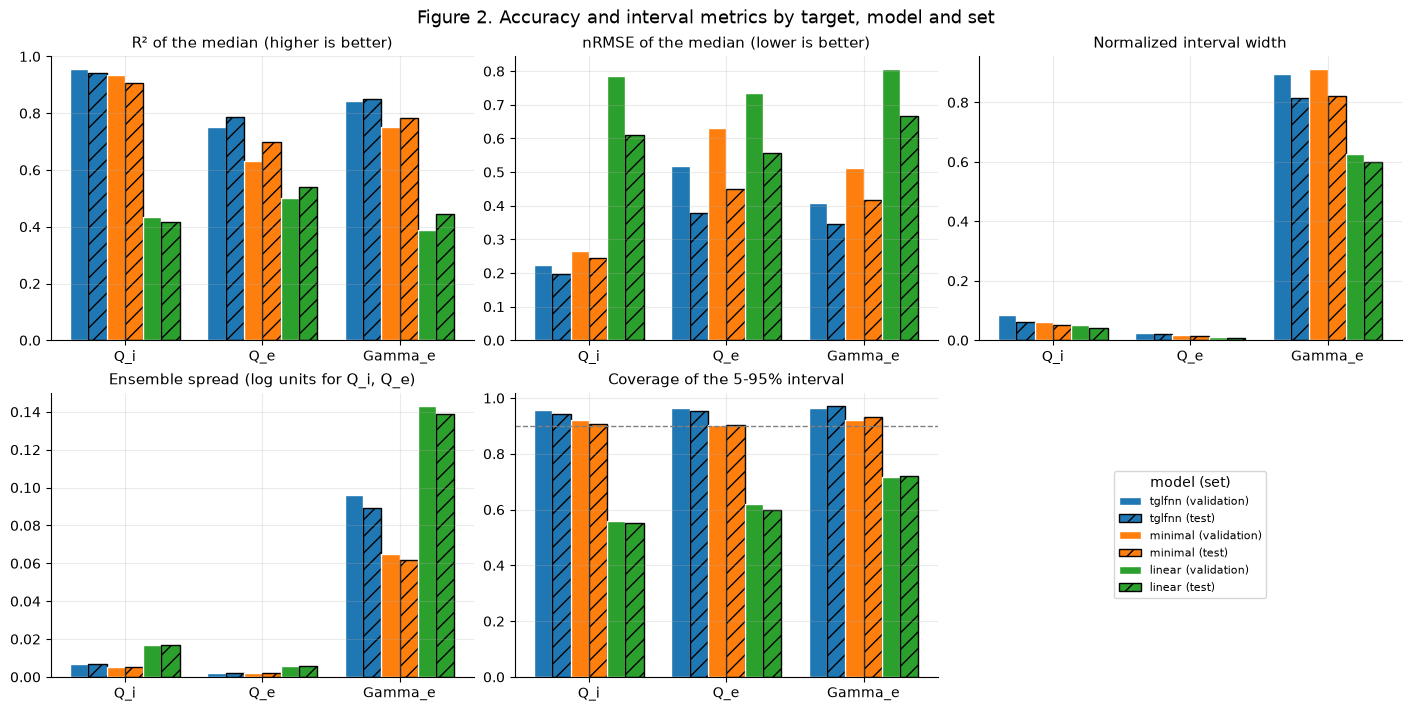

In [207]:
# Figure 2: Table 1 metrics as grouped bars. x = target, one bar per (model, split).
bars = table_1.copy()
bars["model"] = bars["split"].str.split("_").str[0]     # tglfnn / minimal / linear
bars["set"] = bars["split"].str.split("_").str[1]       # validation / test
bars["nwidth (median)"] = bars["width (median)"] / bars["target"].map(dict(zip(TARGET_KEYS, train_sd)))   # width in training standard deviations

METRICS = [
    ("R2 (median)", "R² of the median (higher is better)"),
    ("nRMSE (median)", "nRMSE of the median (lower is better)"),
    ("nwidth (median)", "Normalized interval width"),
    ("spread (median)", "Ensemble spread (log units for Q_i, Q_e)"),
    ("coverage (5-95%)", "Coverage of the 5-95% interval"),
]
MODEL_COLORS = {"tglfnn": "tab:blue", "minimal": "tab:orange", "linear": "tab:green"}
groups = [(m, s) for m in MODEL_COLORS for s in ("validation", "test")]
width_bar = 0.8 / len(groups)
x = np.arange(len(TARGET_KEYS))

fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for ax, (col, title) in zip(axes.flat, METRICS):
    for i, (model, split) in enumerate(groups):
        sub = bars[(bars["model"] == model) & (bars["set"] == split)].set_index("target").loc[TARGET_KEYS]
        ax.bar(x + (i - (len(groups) - 1) / 2) * width_bar, sub[col], width_bar, color=MODEL_COLORS[model],
               hatch="//" if split == "test" else None, edgecolor="white" if split == "validation" else "black",
               label=f"{model} ({split})")
    if col == "coverage (5-95%)":
        ax.axhline(0.9, color="gray", linestyle="--", linewidth=1)
    ax.set(title=title, xticks=x, xticklabels=TARGET_KEYS)
for ax in axes.flat[len(METRICS):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", title="model (set)")
fig.suptitle(fig_title(2, "Accuracy and interval metrics by target, model and set"))
plt.show()


**Figure 3.** Log-ratio plots for all three ensembles (`TGLFNN`, minimal, linear baseline) on the validation and test sets. Each boxed row is one model and set; columns are targets. For $Q_i$ and $Q_e$ the y axis is $\log_{10}(\hat{y}/y)$, the median prediction over the true flux, so 0 is a perfect prediction and +1 is a factor of 10 too high. Points are single cases. The black line is the median log-ratio within equal-count bins of the true flux, and the shaded band is the median 5-95% interval in the same bin, in the same units. Each panel gives the R² of the median prediction and the fraction of cases whose true value falls inside the interval. $\Gamma_e$ can be zero or negative, so a ratio is undefined; its column instead shows $(\hat{y}-y)/\sigma_\mathrm{train}$, the error in training standard deviations, where 0 is again a perfect prediction. Every case is plotted.

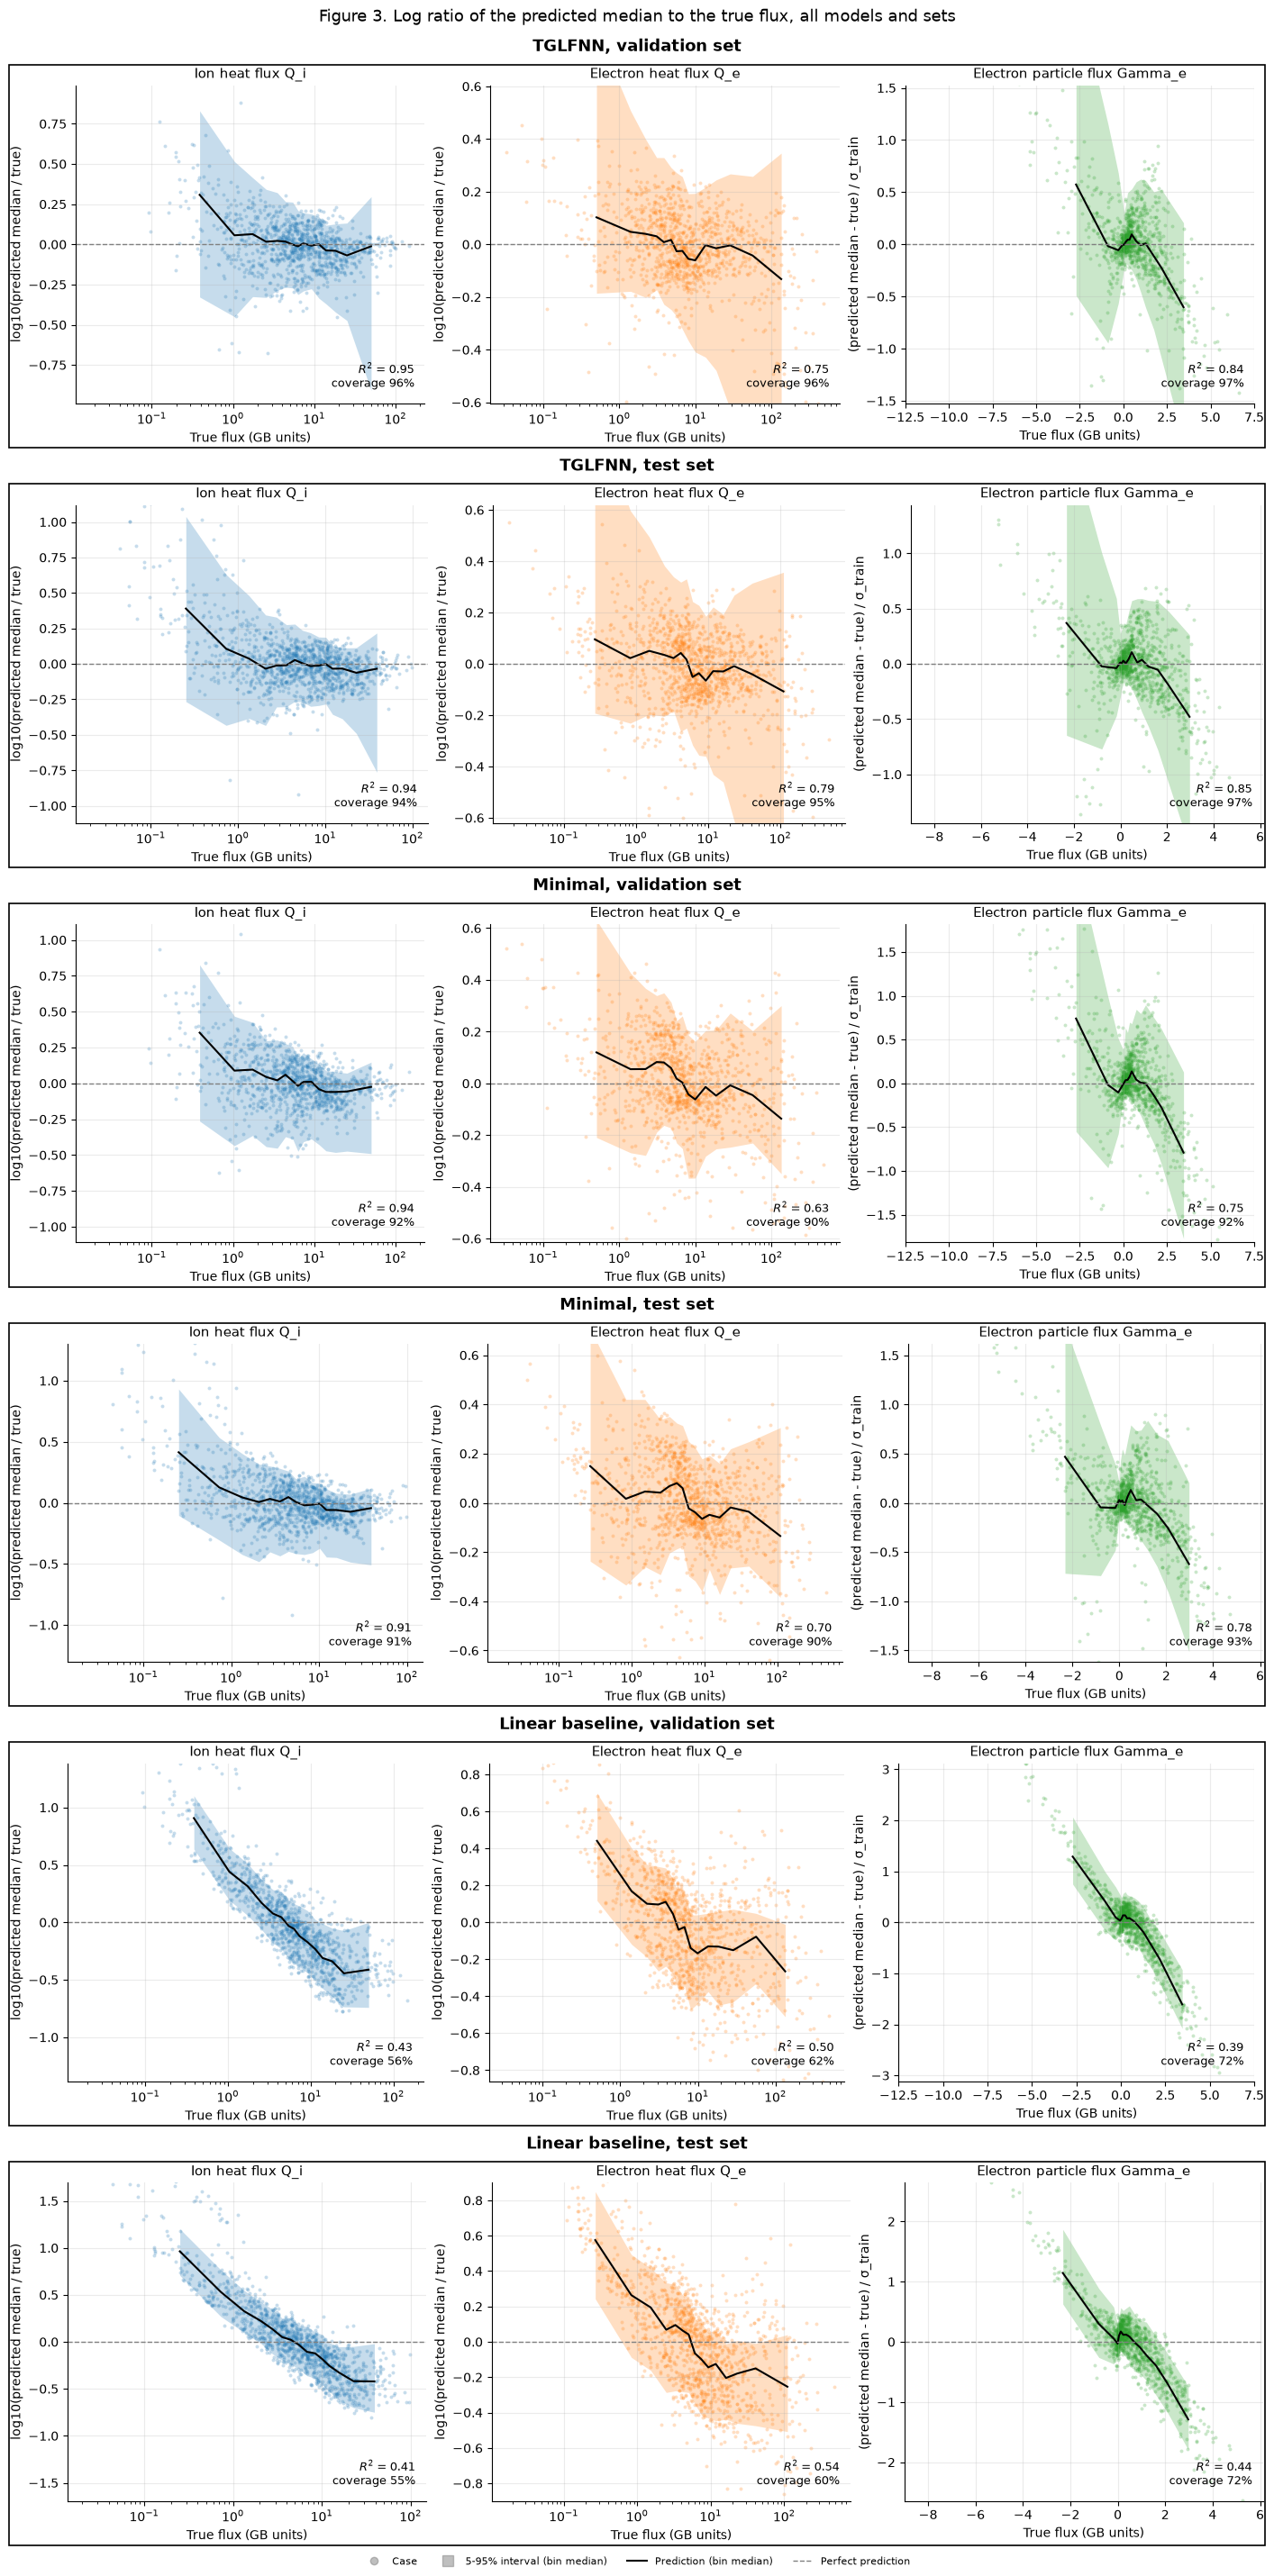

In [208]:
from matplotlib.lines import Line2D

# Figure 3: log10(prediction / true), all models on both sets. Rows = (model, set), columns = target.
# Every case is a faint point; the line and band are per-bin summaries (equal-count bins of the true flux).
# Heat fluxes (always positive): y = log10(pred / true). Gamma_e can be zero or negative, so a ratio is undefined: y = (pred - true) / sigma_train instead.
# In both cases y = 0 is a perfect prediction. Every case is kept.
N_BINS = 15
ROWS = [("tglfnn", "validation"), ("tglfnn", "test"), ("minimal", "validation"), ("minimal", "test"), ("linear", "validation"), ("linear", "test")]
MODEL_LABEL = {"tglfnn": "TGLFNN", "minimal": "Minimal", "linear": "Linear baseline"}

fig = plt.figure(figsize=(14, 28.5), constrained_layout=True)
strips = fig.subfigures(2 * len(ROWS), 1, height_ratios=[0.09, 1] * len(ROWS), hspace=0.0)   # title strip, boxed row, title strip, ...
axes = []
for r, (model, split) in enumerate(ROWS):
    title_strip, row_fig = strips[2 * r], strips[2 * r + 1]
    title_strip.text(0.5, 0.25, f"{MODEL_LABEL[model]}, {split} set", ha="center", va="bottom", fontsize=13, fontweight="bold")
    # the box: a rectangle just inside the row's subfigure, so the line is not clipped at the edge
    row_fig.add_artist(plt.Rectangle((0.002, 0.002), 0.996, 0.996, transform=row_fig.transSubfigure, fill=False, edgecolor="black", linewidth=1.2))
    axes.append(row_fig.subplots(1, 3))
axes = np.array(axes)
for r, (model, split) in enumerate(ROWS):
    bands, y = SPLITS[f"{model}_{split}"]["bands"], SPLITS[f"{model}_{split}"]["y_true"]
    for t, ax in enumerate(axes[r]):
        true = y[:, t]
        low, med, high = bands[:, t, 0], bands[:, t, 1], bands[:, t, 2]
        inside = np.mean((true >= low) & (true <= high))
        r2 = 1 - np.sum((med - true) ** 2) / np.sum((true - true.mean()) ** 2)    # same definition as Table 1

        if LOG_FLUX_AXIS[t]:   # heat flux: log10 of the ratio to the truth
            l_med, l_low, l_high = (np.log10(v / true) for v in (med, low, high))
        else:                  # Gamma_e: difference in training standard deviations
            l_med, l_low, l_high = ((v - true) / train_sd[t] for v in (med, low, high))
        t_ok = true

        # line = median residual in the bin, band = median lower/upper bound
        chunks = np.array_split(np.argsort(t_ok), N_BINS)
        bx = np.array([np.median(t_ok[c]) for c in chunks])
        b_med, b_low, b_high = (np.array([np.median(v[c]) for c in chunks]) for v in (l_med, l_low, l_high))

        ax.scatter(t_ok, l_med, s=8, alpha=0.25, color=TARGET_COLORS[t], linewidths=0, rasterized=True, label="Case")
        ax.fill_between(bx, b_low, b_high, color=TARGET_COLORS[t], alpha=0.25, linewidth=0, label="5-95% interval (bin median)")
        ax.plot(bx, b_med, color="black", linewidth=1.5, label="Prediction (bin median)")
        ax.axhline(0, color="gray", linestyle="--", linewidth=1, label="Perfect prediction")
        if LOG_FLUX_AXIS[t]:
            ax.set_xscale("log")
        lim = np.percentile(np.abs(np.concatenate([l_med, b_low, b_high])), 99)   # symmetric about 0, ignoring a few extreme cases
        ax.set_ylim(-lim, lim)
        ax.text(0.97, 0.04, f"$R^2$ = {r2:.2f}\ncoverage {inside:.0%}", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
        ax.set_title(TARGET_NAMES[t])
        ax.set_xlabel("True flux (GB units)")
        ax.set_ylabel("log10(predicted median / true)" if LOG_FLUX_AXIS[t] else "(predicted median - true) / σ_train")

# one shared legend below the panels; the point and band entries use gray swatches, since the panels are colored by target
handles, labels = axes[0, 0].get_legend_handles_labels()
swatch = {"Case": "o", "5-95% interval (bin median)": "s"}
handles = [Line2D([], [], marker=swatch[l], linestyle="", color="gray", alpha=0.5, markersize=6 if l == "Case" else 9)
           if l in swatch else h for h, l in zip(handles, labels)]
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False, markerscale=1)
fig.suptitle(fig_title(3, "Log ratio of the predicted median to the true flux, all models and sets", note=f"{N_BINS} equal-count bins"))
plt.show()


## 5. Learning curves: how much training data is needed?

The three architectures are refit on growing random subsets of the training set and scored on the fixed validation set. The rows are shuffled once and each subset is a prefix of that shuffle, so every subset contains the one before it. Ten sizes are used, log-spaced from 1% to 100% of the training rows. Every fit uses the training recipe of section 4 with the same seed. The training loss and interval width are read at the last epoch; the validation loss and width come from the fitted model applied to the unchanged validation set. The loss is the pinball loss on the standardized targets and the width is the mean 5-95% interval width in the same units. Only one seed is used per size, so the curves carry some noise.

In [209]:
X_val_t = to_tensor(val_X_scaled.values)
y_val_t = to_tensor((val_y_log_df.values - y_mean) / y_std)

rng = np.random.default_rng(RANDOM_STATE)
perm = rng.permutation(len(train_X_scaled))          # one shuffle -> nested subsets

# sizes: log-spaced, 1% -> 100% of the training set
sizes = np.unique(np.geomspace(0.01 * len(perm), len(perm), 10).astype(int))

MODELS = (("tglfnn", TGLFNN), ("minimal", TGLFNNMinimalHidden), ("linear", TGLFLinear))

rows = []
for n in sizes:
    idx = perm[:n]
    X_sub_t, y_sub_t = X_train_t[idx], y_train_t[idx]   # already scaled; targets standardized log fluxes
    row = {"size": n}
    for name, cls in MODELS:
        model, losses, widths = fit_member(cls, RANDOM_STATE, X_train=X_sub_t, y_train=y_sub_t)
        model.eval()
        with torch.no_grad():
            val_out = sorted_quantiles(model(X_val_t))   # fixed validation set
        row |= {
            f"{name}_train_loss": losses[-1],            # final epoch, not the mean over epochs
            f"{name}_train_width": widths[-1],
            f"{name}_val_loss": pinball_loss(val_out, y_val_t).item(),
            f"{name}_val_width": range_of_quantiles(val_out).mean().item(),
        }
    rows.append(row)

size_df = pd.DataFrame(rows)
size_df

,size,tglfnn_train_loss,tglfnn_train_width,tglfnn_val_loss,tglfnn_val_width,minimal_train_loss,minimal_train_width,minimal_val_loss,minimal_val_width,linear_train_loss,linear_train_width,linear_val_loss,linear_val_width
0,50,0.043877,1.264121,0.095350,1.136948,0.039799,0.838634,0.105919,0.815288,0.134233,0.802794,0.139786,0.795267
1,83,0.043622,1.135913,0.084677,1.067529,0.043115,0.907713,0.089419,0.905765,0.142061,0.780704,0.135908,0.795375
2,139,0.042452,0.903805,0.078045,0.917377,0.050820,1.009397,0.086979,1.035342,0.140139,0.762116,0.138789,0.769382
3,233,0.046239,0.922044,0.068917,0.940319,0.054823,1.062370,0.076732,1.093106,0.145842,0.750853,0.137934,0.763567
4,388,0.049039,0.985550,0.060889,1.003440,0.061792,1.189531,0.073721,1.211919,0.151008,0.744071,0.138801,0.744682
5,648,0.051634,1.011322,0.058804,1.006542,0.065074,1.202942,0.072473,1.206314,0.154149,0.752456,0.137848,0.748346
6,1081,0.052251,1.016204,0.056751,1.013598,0.065973,1.208645,0.071821,1.215646,0.154882,0.737378,0.138181,0.742505
7,1804,0.054041,1.041855,0.055877,1.033471,0.066990,1.212472,0.070975,1.223657,0.158149,0.743505,0.137645,0.750402
8,3010,0.057310,1.198351,0.057752,1.163870,0.067099,1.221197,0.070324,1.232908,0.158463,0.735909,0.138092,0.745515
9,5022,0.055033,1.051412,0.054331,1.040497,0.068631,1.227258,0.070369,1.233698,0.160001,0.740493,0.137826,0.746772


**Figure 4.** Pinball loss (left) and mean 5-95% interval width (right) against the number of training rows (log scale), for all three models. Solid lines are the validation set, dashed lines the training set. A validation loss that is still falling at the largest size means more data would help, and a growing gap between the dashed and solid loss lines means overfitting. A loss that is flat in the size, as for the linear baseline, is limited by the model and not by the amount of data.

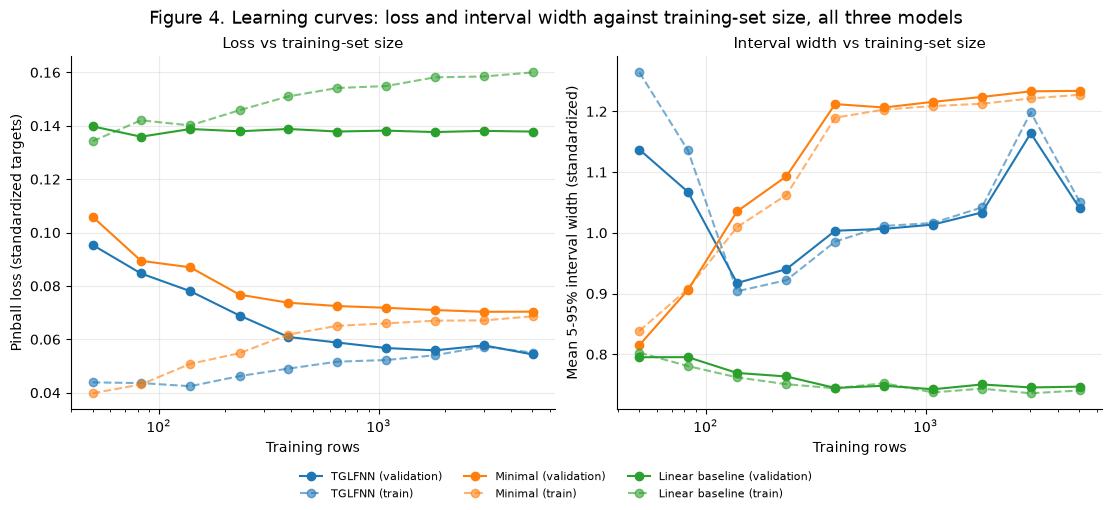

In [210]:
# learning curves: loss and interval width vs training-set size (solid = validation, dashed = training)
CURVE_COLORS = {"tglfnn": "tab:blue", "minimal": "tab:orange", "linear": "tab:green"}
CURVE_LABELS = {"tglfnn": "TGLFNN", "minimal": "Minimal", "linear": "Linear baseline"}

fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, (metric, ylabel, title) in zip(axes, [
    ("loss", "Pinball loss (standardized targets)", "Loss vs training-set size"),
    ("width", "Mean 5-95% interval width (standardized)", "Interval width vs training-set size"),
]):
    for name in CURVE_COLORS:
        if f"{name}_val_{metric}" not in size_df:   # rerun the loop cell if a model is missing
            continue
        ax.plot(size_df["size"], size_df[f"{name}_val_{metric}"], color=CURVE_COLORS[name], marker="o", label=f"{CURVE_LABELS[name]} (validation)")
        ax.plot(size_df["size"], size_df[f"{name}_train_{metric}"], color=CURVE_COLORS[name], marker="o", linestyle="--", alpha=0.6, label=f"{CURVE_LABELS[name]} (train)")
    ax.set(xscale="log", xlabel="Training rows", ylabel=ylabel, title=title)

# one shared legend below both panels, so it never covers the curves
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("Figure 4. Learning curves: loss and interval width against training-set size, all three models")
plt.show()

## 6. Band, width and spread against the input parameters

**Table 2.** The validation cases of the TGLFNN ensemble in one table. The first columns are the inputs the models use, each in standard deviations from the validation-set mean (the scaled inputs of step 2, standardized once more with the validation set's own mean and standard deviation). Next come the band of each output (`_low`, `_median`, `_high`, in flux units), the interval width (`_width`, upper minus lower, in flux units) and the ensemble spread (`_spread`, the standard deviation of the median across the members; log units for $Q_i$ and $Q_e$).

In [211]:
input_features_mean = val_X_scaled.mean()
input_features_std = val_X_scaled.std()
input_features_stds_away = (val_X_scaled - input_features_mean) / input_features_std

bands, spread, width = predict_ensemble(tglfnn_ensemble, val_X_scaled)
bands_cols = [f"{t}_{q}" for t in TARGET_KEYS for q in ("low", "median", "high")]
width_cols = [f"{t}_width" for t in TARGET_KEYS]
spread_cols = [f"{t}_spread" for t in TARGET_KEYS]
bands_df = pd.DataFrame(bands.reshape(len(bands), -1), columns=bands_cols, index=val_X_scaled.index)
widths_df = pd.DataFrame(width, columns=width_cols, index=val_X_scaled.index)
spread_df = pd.DataFrame(spread, columns=spread_cols, index=val_X_scaled.index)

merged_input_features = pd.concat([input_features_stds_away, bands_df, widths_df, spread_df], axis=1)
merged_input_features

,r_over_a,XNUE,RLNS_e,RLTS_e,RLTS_i,TAUS_i,Q_i_low,Q_i_median,Q_i_high,Q_e_low,...,Q_e_high,Gamma_e_low,Gamma_e_median,Gamma_e_high,Q_i_width,Q_e_width,Gamma_e_width,Q_i_spread,Q_e_spread,Gamma_e_spread
3,-0.861787,-0.335015,-0.002484,-0.279409,-0.839443,-1.542008,0.477876,1.050900,2.892308,0.525412,...,5.276870,-0.122727,0.103012,0.477453,2.414432,4.751458,0.600180,0.125422,0.098133,0.060692
6,-0.037906,0.048711,-0.472597,-0.648472,0.782248,-0.723534,4.741933,7.699471,11.206718,2.561278,...,6.469542,0.311344,0.655742,1.258257,6.464785,3.908264,0.946913,0.081650,0.044465,0.087017
10,1.060603,0.277425,-0.265831,0.229637,-0.911952,1.242648,1.162246,4.696792,7.932517,3.817310,...,40.937257,-1.219122,-0.187670,1.085243,6.770272,37.119947,2.304366,0.066146,0.096210,0.107762
11,1.335230,1.175256,-0.546920,1.315770,-0.506262,0.779338,0.467068,4.739544,10.310704,3.695239,...,108.490810,-2.869843,-1.435102,0.654728,9.843636,104.795571,3.524571,0.097315,0.100732,0.172059
12,1.609858,1.497037,1.440476,2.440545,0.819419,2.548413,1.849238,26.664842,69.473595,6.694752,...,242.191339,-3.127248,-0.569265,2.736021,67.624357,235.496587,5.863269,0.094727,0.123010,0.158056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7364,1.609858,1.653785,0.210345,3.064491,0.380033,0.247450,0.272074,7.075131,21.223449,3.200089,...,280.630303,-4.609127,-2.536083,0.750594,20.951375,277.430214,5.359720,0.238716,0.185240,0.206022
7366,-1.411042,-0.584946,0.580869,-0.561681,-0.664853,-1.007329,1.392252,2.660289,5.282811,0.920724,...,4.658783,0.182207,0.510443,1.107406,3.890560,3.738058,0.925199,0.040257,0.078793,0.062609
7368,-0.861787,-0.794458,2.037907,-1.005020,0.026481,-1.250365,4.721155,7.822836,19.177156,3.778894,...,14.590072,0.675864,2.622468,3.748644,14.456002,10.811178,3.072780,0.096923,0.136585,0.143429
7369,-0.587160,-0.248312,-0.311017,-0.853540,-1.223350,-0.119995,0.335422,0.862331,2.336413,0.371959,...,4.186883,-0.158255,-0.001024,0.153798,2.000991,3.814924,0.312053,0.162574,0.109296,0.164679


Where does the model change its prediction, and where is it least certain? Each figure plots one quantity against the inputs that survive step 2 (`r_over_a`, `XNUE`, `RLNS_e`, `RLTS_e`, `RLTS_i`, `TAUS_i`). Lines are medians in `N_INPUT_BINS` equal-count bins of the input. The horizontal axis is set by `x_axis`: `raw` is the input in its original units, `scaled` is the standardized value $z = (x - \mu_\mathrm{train}) / \sigma_\mathrm{train}$ with its sign, and `distance` is $|z|$, how far the input is from its training mean regardless of direction.

- **Figure 5:** the band. Rows are the outputs and columns the inputs. The black line is the median prediction, the shaded region lies between the 5% and 95% bounds, and the faint points are single cases. Heat fluxes are on a log axis.
- **Figures 6 and 7:** the interval width and the ensemble spread. One panel per input and one line per output. Both are divided by the training standard deviation of the output, so the three outputs share an axis. Each figure is drawn twice, against $|z|$ and against the signed $z$.

Inputs also move the flux itself, so a wide interval at some input value can reflect a high flux there and not only a lack of data.

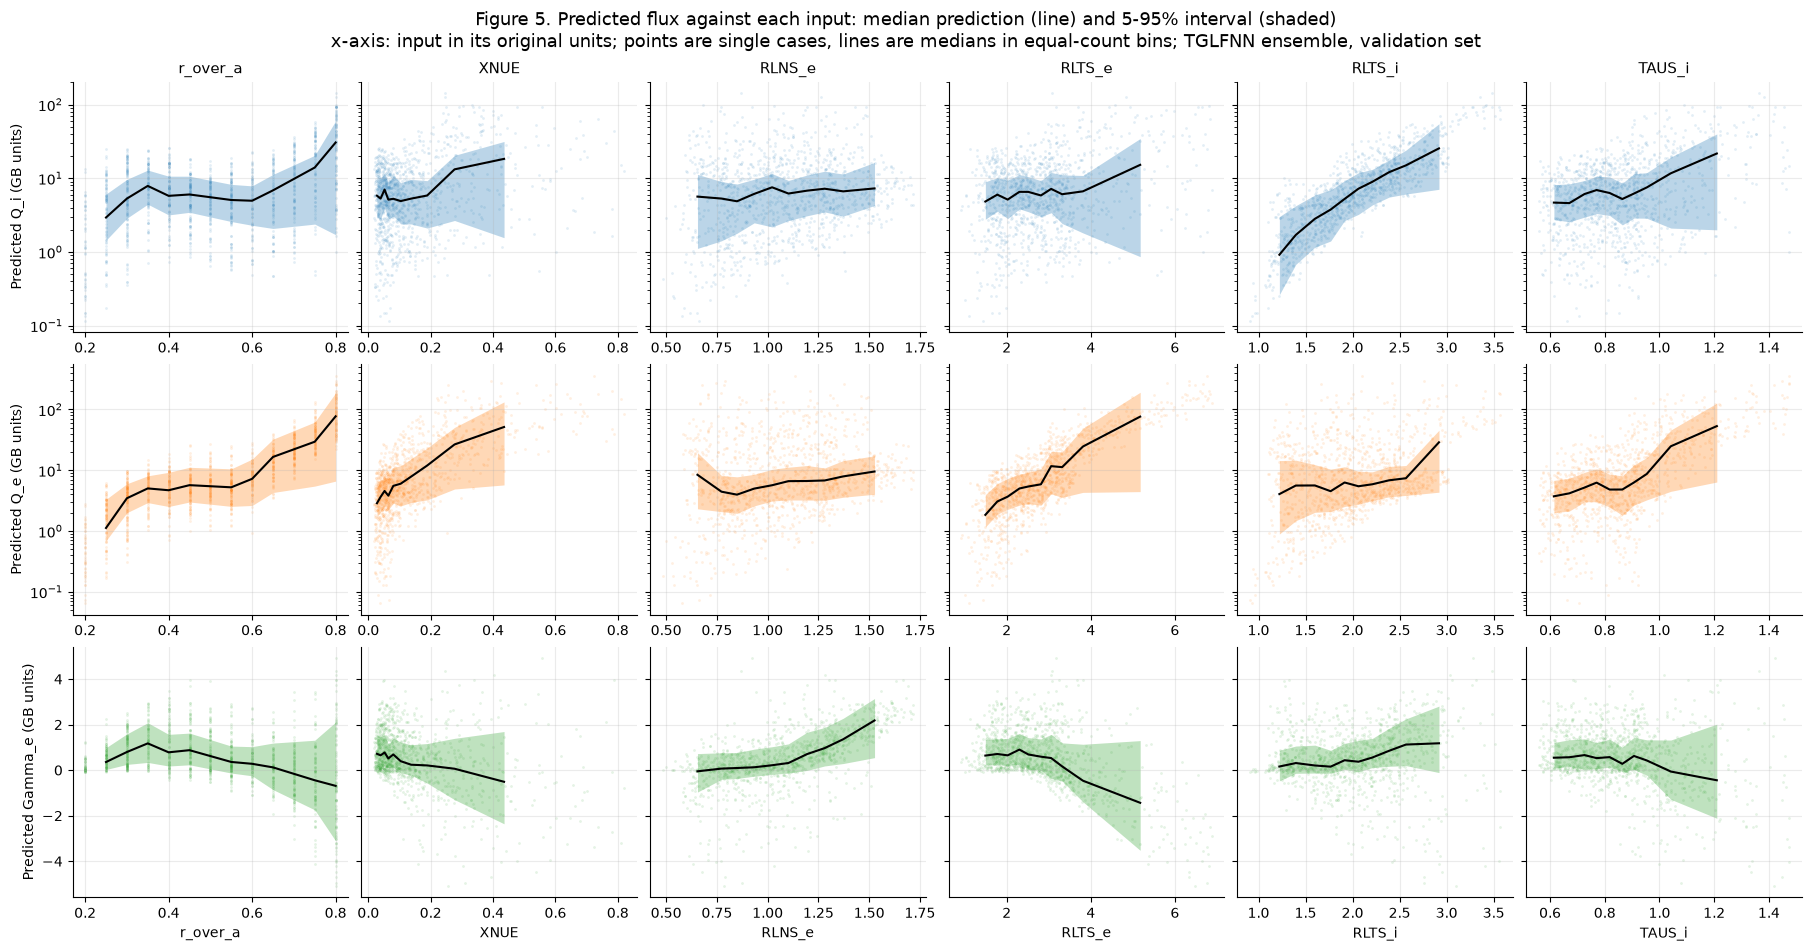

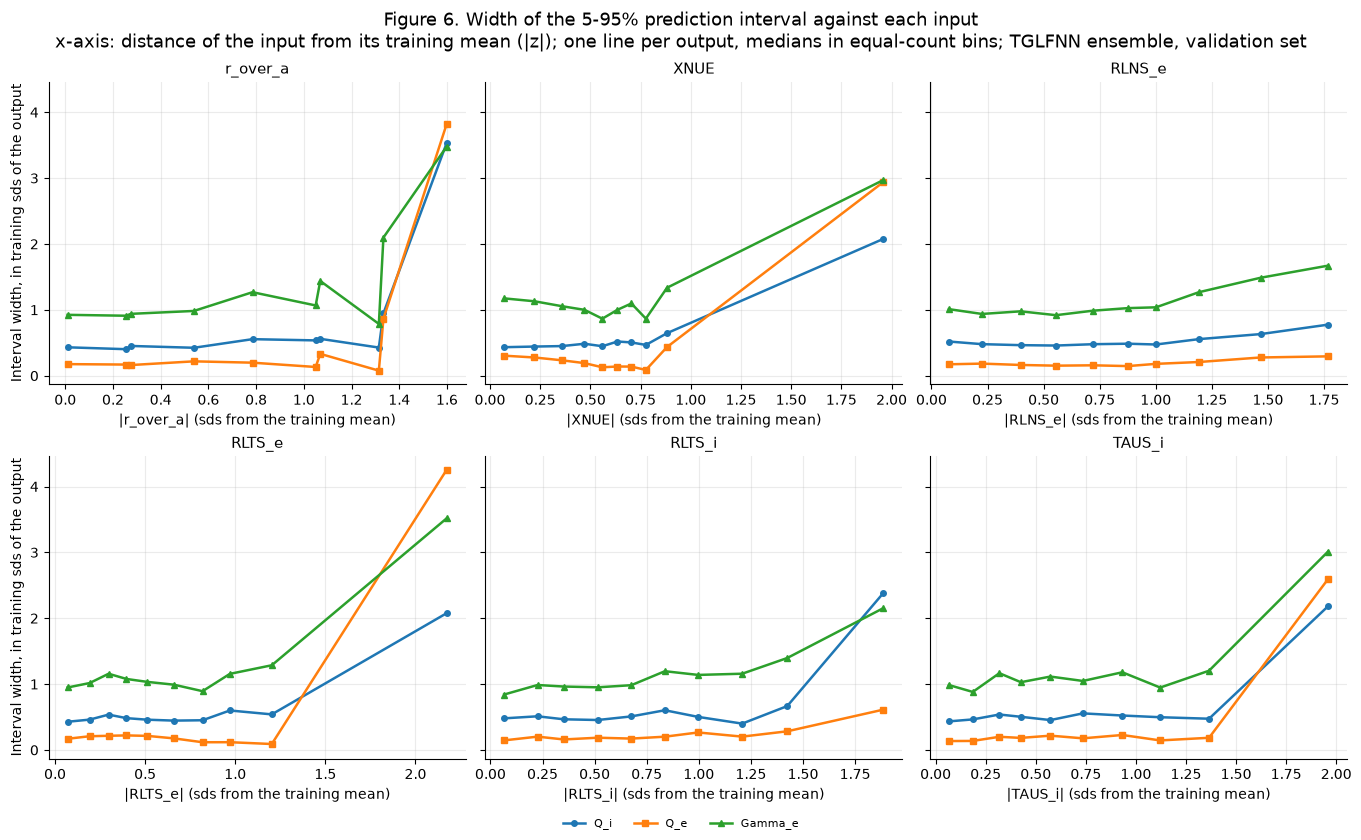

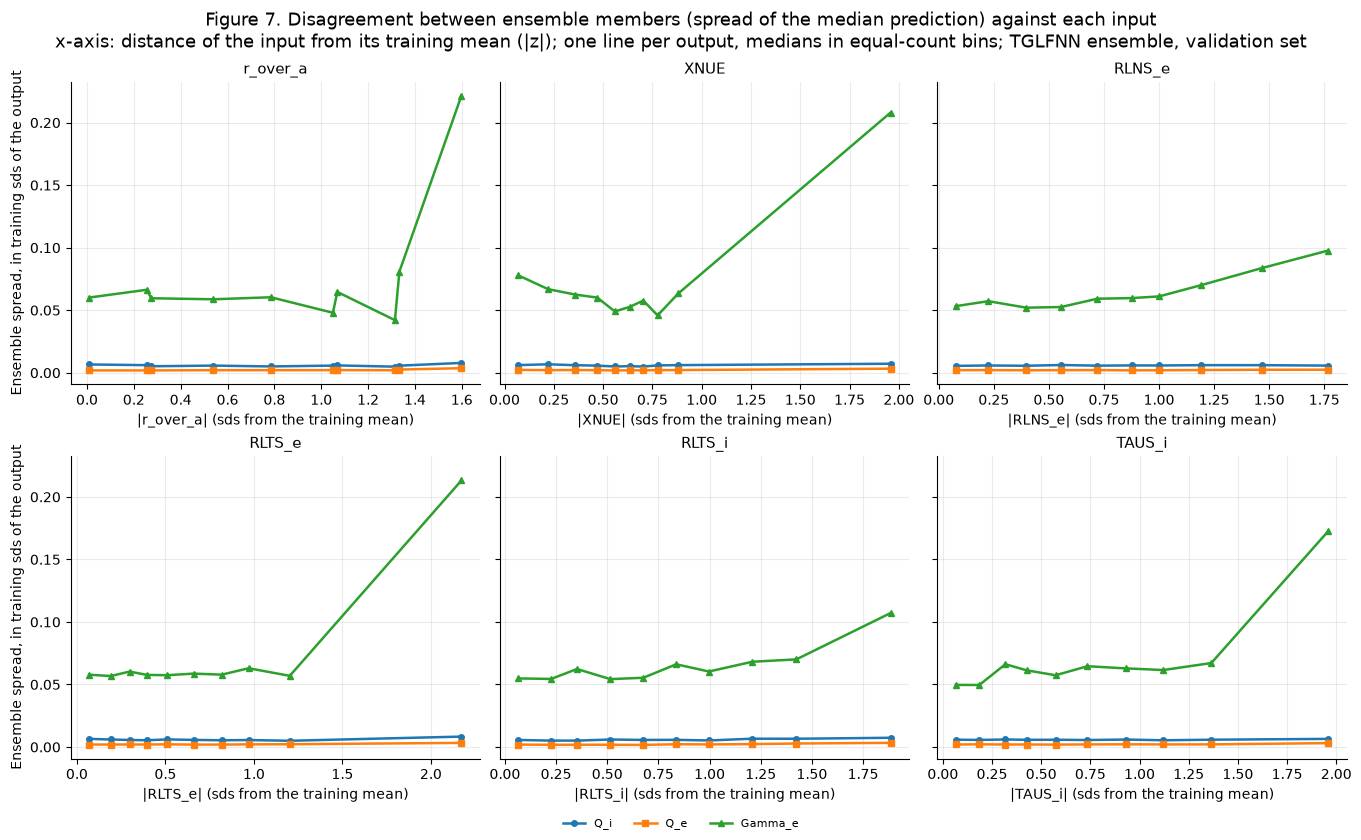

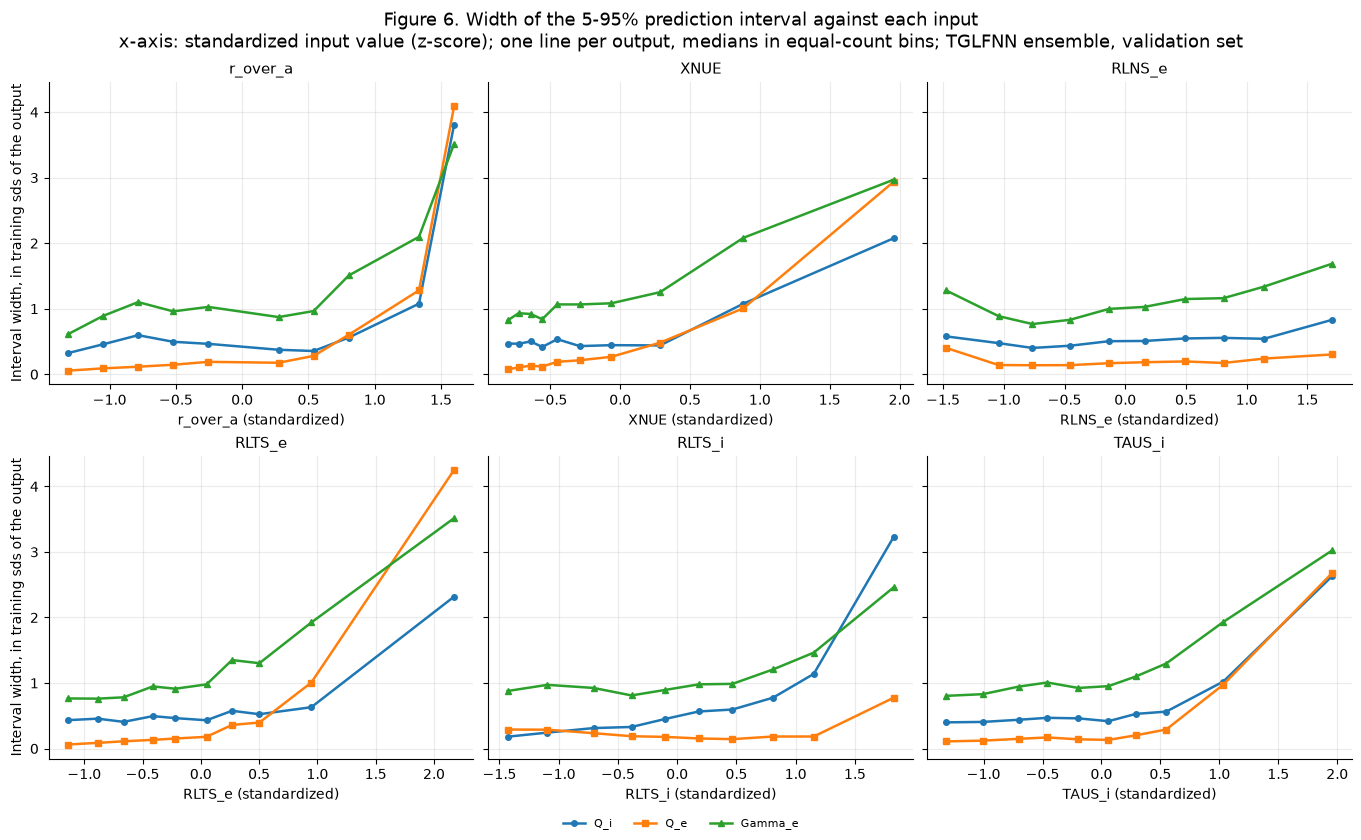

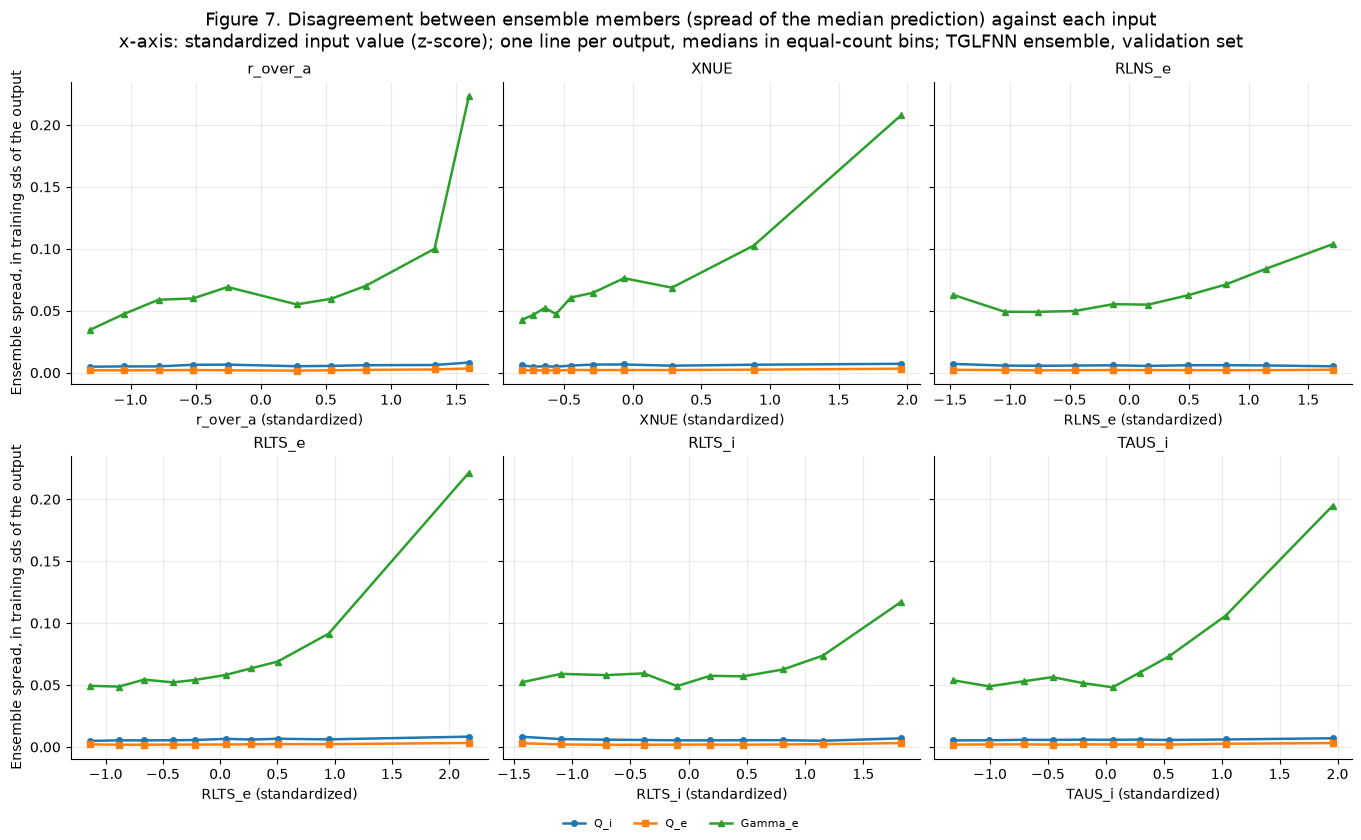

In [212]:
# how the model's output changes with each input feature. Lines are medians within equal-count bins of the feature.
#   Figure A: the band, rows = targets, columns = features (black line = median prediction, shaded = 5-95% interval, faint points = single cases)
#   Figure B: interval width vs each feature, one panel per feature, one line per target
#   Figure C: ensemble spread vs each feature, one panel per feature, one line per target
# width and spread are divided by the training sd of each target, so the three targets share one axis.
#
# x_axis chooses what each feature is plotted against:
#   "raw"      the input in its original units
#   "scaled"   the standardized value z = (x - training mean) / training sd, signed
#   "distance" the distance from the training mean, |z|
SCALED_X = {"validation": val_X_scaled, "test": test_X_scaled}
X_AXIS_LABEL = {"raw": "{}", "scaled": "{} (standardized)", "distance": "|{}| (sds from the training mean)"}
X_AXIS_DESC = {"raw": "input in its original units", "scaled": "standardized input value (z-score)", "distance": "distance of the input from its training mean (|z|)"}
MODEL_NAMES = {"tglfnn": "TGLFNN ensemble", "minimal": "minimal one-layer ensemble", "linear": "linear baseline ensemble"}

def describe_split(split):
    model, dataset = split.split("_")
    return f"{MODEL_NAMES[model]}, {dataset} set"

def feature_values(split, x_axis):
    X = SPLITS[split]["X"]
    if x_axis == "raw":
        return X
    scaled = SCALED_X[split.split("_")[-1]]
    return scaled if x_axis == "scaled" else scaled.abs()

def feature_bins(x, n_bins):
    values = np.unique(x)
    groups = [np.where(x == v)[0] for v in values] if values.size <= 2 else np.array_split(np.argsort(x), n_bins)
    return groups, np.array([np.median(x[g]) for g in groups])

def plot_feature_band(split="tglfnn_validation", x_axis="raw", n_bins=N_INPUT_BINS):
    s = SPLITS[split]
    X = feature_values(split, x_axis)
    fig, axes = plt.subplots(3, X.shape[1], figsize=(3.0 * X.shape[1], 9.4), sharey="row", constrained_layout=True, squeeze=False)
    for c, feat in enumerate(X.columns):
        x = X[feat].to_numpy()
        groups, bx = feature_bins(x, n_bins)
        for t in range(3):
            ax = axes[t, c]
            low, med, high = (np.array([np.median(s["bands"][g, t, q]) for g in groups]) for q in range(3))
            ax.scatter(x, s["bands"][:, t, 1], s=4, alpha=0.12, color=TARGET_COLORS[t], linewidths=0, rasterized=True)
            ax.fill_between(bx, low, high, color=TARGET_COLORS[t], alpha=0.3, linewidth=0)
            ax.plot(bx, med, color="black", linewidth=1.5)
            if LOG_FLUX_AXIS[t]:
                ax.set_yscale("log")
            if t == 0:
                ax.set_title(feat)
            if t == 2:
                ax.set_xlabel(X_AXIS_LABEL[x_axis].format(feat))
            if c == 0:
                ax.set_ylabel(f"Predicted {TARGET_KEYS[t]} (GB units)")
    fig.suptitle(f"Figure 5. Predicted flux against each input: median prediction (line) and 5-95% interval (shaded)\n"
                 f"x-axis: {X_AXIS_DESC[x_axis]}; points are single cases, lines are medians in equal-count bins; {describe_split(split)}")
    plt.show()

def plot_feature_metric(kind, split="tglfnn_validation", x_axis="raw", n_bins=N_INPUT_BINS, n_cols=3):
    """kind: 'width' or 'spread'. One panel per feature, three lines (one per target) in each."""
    s = SPLITS[split]
    X = feature_values(split, x_axis)
    n_rows = int(np.ceil(X.shape[1] / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3.6 * n_rows + 1.1), sharey=True, constrained_layout=True, squeeze=False)
    for ax, feat in zip(axes.flat, X.columns):
        groups, bx = feature_bins(X[feat].to_numpy(), n_bins)
        for t in range(3):
            ax.plot(bx, [np.median(s[kind][g, t]) / train_sd[t] for g in groups], color=TARGET_COLORS[t], marker=TARGET_MARKERS[t], markersize=4, linewidth=1.8, label=TARGET_KEYS[t])
        ax.set(xlabel=X_AXIS_LABEL[x_axis].format(feat), title=feat)
    for ax in axes.flat[X.shape[1]:]:
        ax.axis("off")
    for row in axes:
        row[0].set_ylabel("Interval width, in training sds of the output" if kind == "width" else "Ensemble spread, in training sds of the output")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
    what = ("Width of the 5-95% prediction interval" if kind == "width"
            else "Disagreement between ensemble members (spread of the median prediction)")
    fig.suptitle(f"Figure {6 if kind == 'width' else 7}. {what} against each input\nx-axis: {X_AXIS_DESC[x_axis]}; one line per output, medians in equal-count bins; {describe_split(split)}")
    plt.show()

plot_feature_band()                                       # original units
for x_axis in ("distance", "scaled"):                     # |z| and the signed standardized value
    plot_feature_metric("width", x_axis=x_axis)
    plot_feature_metric("spread", x_axis=x_axis)

**Figure 8.** Spearman correlation between each input and the relative band width, one bar per output (validation set). The relative band width is $\ln(\mathrm{upper} / \mathrm{lower})$ for $Q_i$ and $Q_e$ and $(\mathrm{upper} - \mathrm{lower}) / \mathrm{median}$ for $\Gamma_e$, used only where the median is positive. A positive bar means a larger input goes with a wider interval, a negative bar with a narrower one. The definition is the same as in `tglf_uncertainty.ipynb` (Figure 8). Spearman's $\rho$ is rank-based, so it does not assume a straight line.

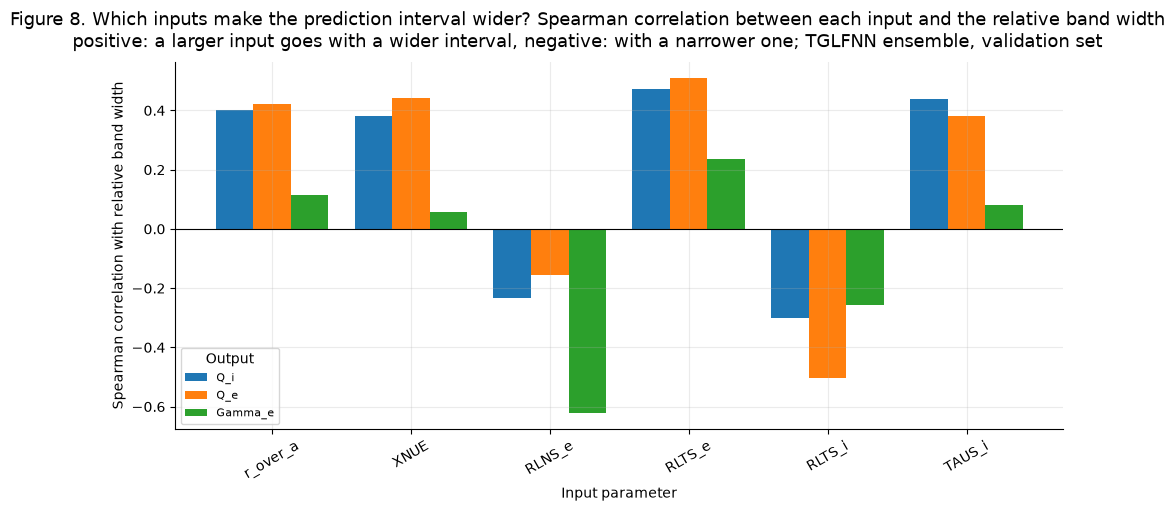

,Q_i,Q_e,Gamma_e
r_over_a,0.400,0.422,0.114
XNUE,0.382,0.441,0.057
RLNS_e,-0.235,-0.155,-0.620
RLTS_e,0.473,0.509,0.235
RLTS_i,-0.301,-0.504,-0.256
TAUS_i,0.440,0.381,0.082


In [213]:
# Spearman correlation between each input and the relative band width (same definition as tglf_uncertainty.ipynb, Figure 8)
# relative band width: heat fluxes ln(upper / lower); Gamma_e (upper - lower) / median, defined only where the median is > 0.
# negative correlation: a larger input goes with a narrower interval.
MODEL_NAMES = {"tglfnn": "TGLFNN ensemble", "minimal": "minimal one-layer ensemble", "linear": "linear baseline ensemble"}

def describe_split(split):
    model, dataset = split.split("_")
    return f"{MODEL_NAMES[model]}, {dataset} set"

def relative_band_width(bands, t):
    lower, median, upper = bands[:, t, 0], bands[:, t, 1], bands[:, t, 2]
    if t < 2:
        return np.log(upper / lower), np.ones(len(lower), dtype=bool)
    ok = median > 0
    return np.where(ok, (upper - lower) / np.where(ok, median, 1.0), np.nan), ok

def plot_width_correlation(split="tglfnn_validation"):
    bands, X = SPLITS[split]["bands"], SPLITS[split]["X"]
    features = list(X.columns)
    rho = pd.DataFrame(index=features, columns=TARGET_KEYS, dtype=float)
    for t in range(3):
        width, ok = relative_band_width(bands, t)
        for feature in features:
            rho.loc[feature, TARGET_KEYS[t]] = pd.Series(X[feature].to_numpy()[ok]).corr(pd.Series(width[ok]), method="spearman")

    fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(features)), 5), constrained_layout=True)
    positions = np.arange(len(features))
    for t in range(3):
        ax.bar(positions + (t - 1) * 0.27, rho[TARGET_KEYS[t]], width=0.27, color=TARGET_COLORS[t], label=TARGET_KEYS[t])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xticks=positions, xticklabels=features, xlabel="Input parameter", ylabel="Spearman correlation with relative band width")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Output")
    fig.suptitle("Figure 8. Which inputs make the prediction interval wider? Spearman correlation between each input and the relative band width\n"
                 f"positive: a larger input goes with a wider interval, negative: with a narrower one; {describe_split(split)}")
    plt.show()
    return rho.round(3)

plot_width_correlation()

## 7. Held-out profile

`data/d3d_profile_second_table.csv` holds a second DIII-D profile: 13 radii from $r/a = 0.20$ to $0.80$, run with TGLF but never used for training, validation or testing. It was read with `../tglf_dataset.py`. The cell below puts it on the same footing as the training data. Species `_1` / `_2` are renamed to `_e` / `_i`, the targets are $Q_e$ = `energy_flux_1`, $Q_i$ = `energy_flux_2` and $\Gamma_e$ = `particle_flux_1`, `r_over_a` is `RMIN_LOC`, only the columns that survive step 2 are kept, and the inputs are scaled with the **training** scaler (nothing is refit). It also counts the cases whose inputs lie outside the training range. The three ensembles then predict, and **Table 3** scores them like Table 1.

With only 13 cases the metrics are noisy: coverage moves in steps of 1/13 and $R^2$ is computed on a small sample.

In [214]:
# held-out set: the second DIII-D profile (13 radii), never used for training, validation or testing
# same steps as step 2: rename species 1/2 -> e/i, build the three targets, keep the columns the models use, scale with the TRAINING scaler
PROFILE2_CSV = DATA_DIR / "d3d_profile_second_table.csv"
MODEL_KEYS = ("tglfnn", "minimal", "linear")
ENSEMBLES = {"tglfnn": tglfnn_ensemble, "minimal": minimal_ensemble, "linear": linear_ensemble}

raw = pd.read_csv(PROFILE2_CSV, index_col=0)
raw = raw.rename(columns=lambda c: c[:-2] + "_e" if c.endswith("_1") else c[:-2] + "_i" if c.endswith("_2") else c)
raw = raw.rename(columns={"energy_flux_e": "Q_e", "energy_flux_i": "Q_i", "particle_flux_e": "Gamma_e"})   # same mapping as the team databases
raw["r_over_a"] = raw["RMIN_LOC"]                                                                        # identical to r_over_a in the team databases

missing = [c for c in train_X_df.columns if c not in raw.columns]
assert not missing, f"held-out table lacks model inputs: {missing}"
X_p2_df, y_p2_df = raw[list(train_X_df.columns)], raw[OUTPUT_COLS]            # the columns that survived step 2 (same order)
keep = valid_rows(X_p2_df, y_p2_df)
print(f"held-out profile: {int(keep.sum())} valid cases of {len(keep)}")
X_p2_df, y_p2_df = X_p2_df[keep], y_p2_df[keep]

continuous_cols = list(scaler.feature_names_in_)
X_p2_scaled = X_p2_df.copy()
X_p2_scaled[continuous_cols] = scaler.transform(X_p2_df[continuous_cols])    # training mean / sd, nothing refit

# how far outside the training range are the held-out inputs?
outside = ((X_p2_df < train_X_df.min()) | (X_p2_df > train_X_df.max())).sum()
print("held-out cases outside the training range, per input:", outside.to_dict())

for m in MODEL_KEYS:
    bands, spread, width = predict_ensemble(ENSEMBLES[m], X_p2_scaled)
    SPLITS[f"{m}_profile2"] = {"bands": bands, "spread": spread, "width": width, "y_true": y_p2_df.values, "X": X_p2_df}

print("Table 3. Accuracy of the median prediction and coverage of the 5-95% interval on the held-out profile (nominal coverage 0.90)")
table_p2 = pd.concat([evaluate(f"{m}_profile2") for m in MODEL_KEYS], ignore_index=True).round(3)
table_p2

held-out profile: 13 valid cases of 13
held-out cases outside the training range, per input: {'r_over_a': 0, 'XNUE': 0, 'RLNS_e': 9, 'RLTS_e': 1, 'RLTS_i': 0, 'TAUS_i': 0}
Table 3. Accuracy of the median prediction and coverage of the 5-95% interval on the held-out profile (nominal coverage 0.90)


,split,target,R2 (median),nRMSE (median),spread (median),width (median),coverage (5-95%)
0,tglfnn_profile2,Q_i,-0.989,0.437,0.017,0.944,0.923
1,tglfnn_profile2,Q_e,-1.754,0.190,0.006,0.401,1.000
2,tglfnn_profile2,Gamma_e,-1.405,0.287,0.103,1.354,1.000
3,minimal_profile2,Q_i,-0.813,0.417,0.009,0.752,0.769
4,minimal_profile2,Q_e,-1.997,0.199,0.003,0.380,0.615
5,minimal_profile2,Gamma_e,-3.114,0.375,0.093,1.254,0.692
6,linear_profile2,Q_i,-0.879,0.424,0.014,0.668,0.846
7,linear_profile2,Q_e,-34.393,0.683,0.008,0.603,0.615
8,linear_profile2,Gamma_e,-2.399,0.341,0.281,1.198,1.000


**Figures 2c and 3c.** The held-out versions of Figures 2 and 3 (the letter c marks the held-out profile; a and b are the validation and test sets). Figure 2c shows every Table 3 metric by output and model. Width and spread are in training standard deviations and the dashed line in the coverage panel is the nominal 0.90. Figure 3c plots $\log_{10}(\hat{y}/y)$, the predicted median over the true flux, for $Q_i$ and $Q_e$, and $(\hat{y} - y)/\sigma_\mathrm{train}$ for $\Gamma_e$, which can be zero or negative; 0 is a perfect prediction. Each point is one case and the vertical bar is its 5-95% interval in the same units. There are too few cases for the binned lines of Figure 3.

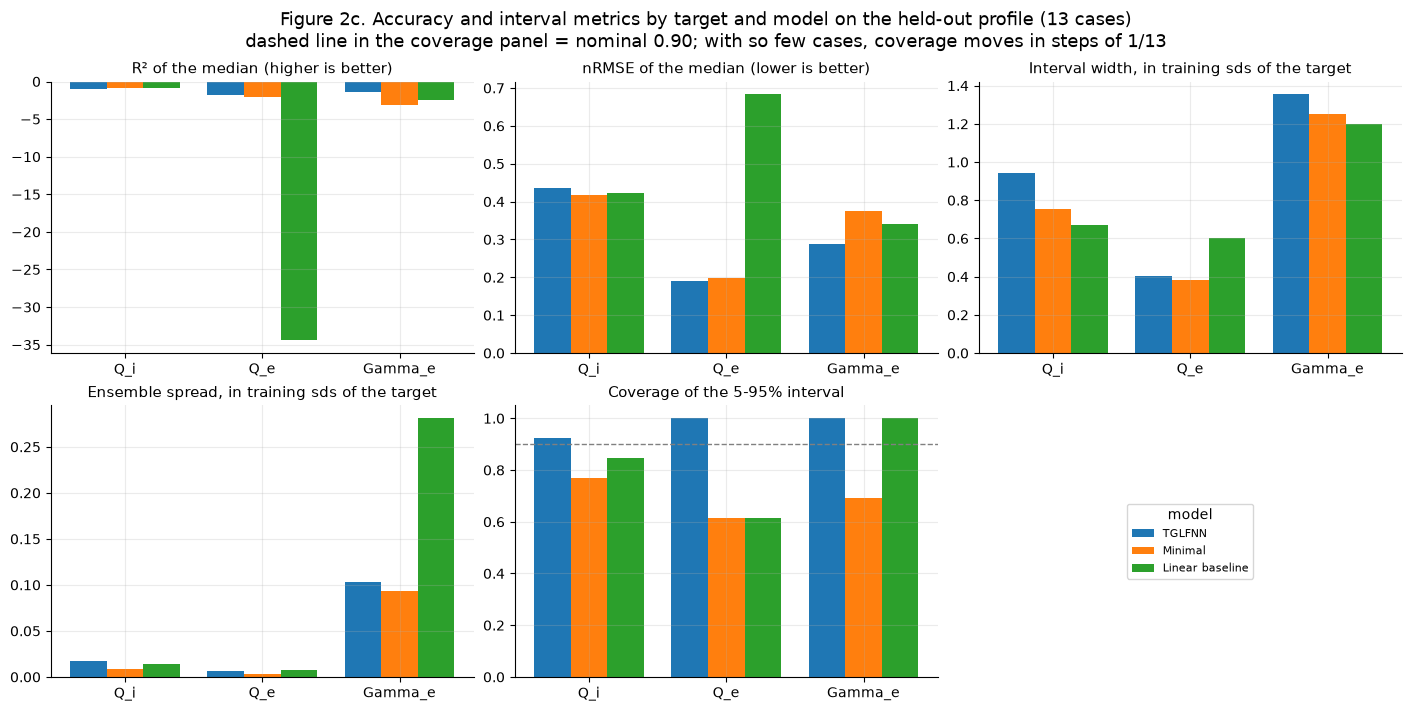

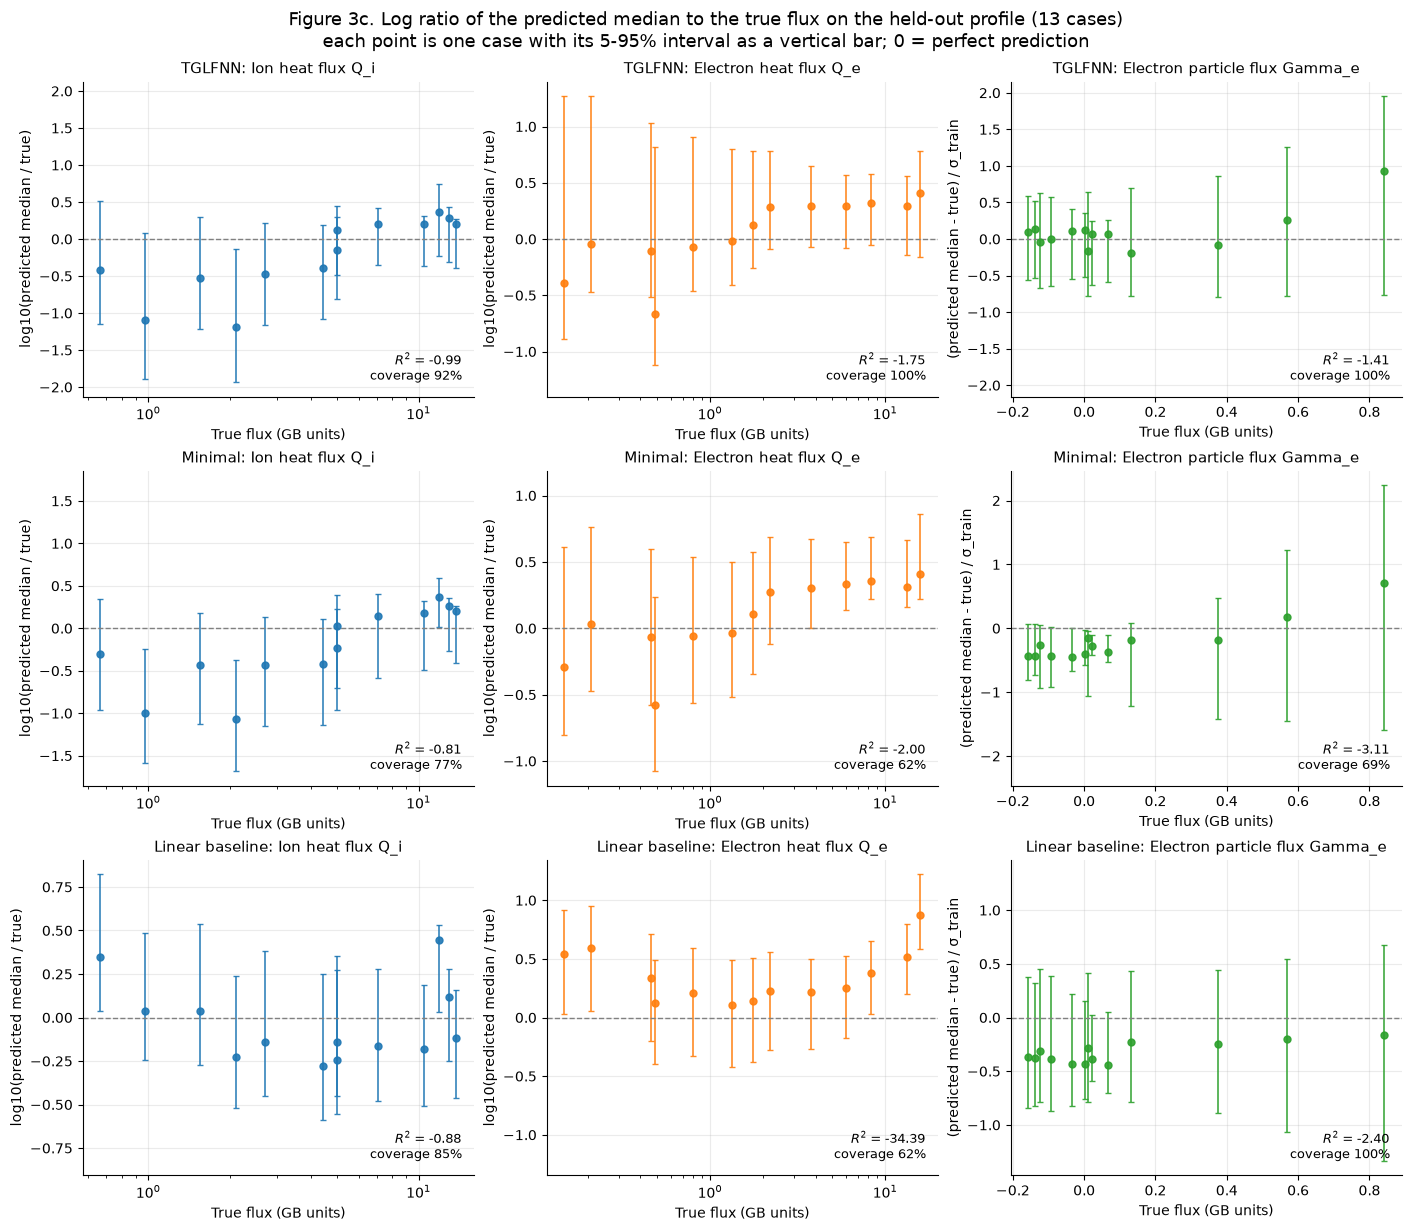

In [215]:
# Figure 2 and Figure 3 for the held-out profile (same layout as the validation / test versions)
P2_COLORS = {"tglfnn": "tab:blue", "minimal": "tab:orange", "linear": "tab:green"}
P2_LABELS = {"tglfnn": "TGLFNN", "minimal": "Minimal", "linear": "Linear baseline"}
n_p2 = len(y_p2_df)

# ---- Figure 2: metrics by target and model
p2 = table_p2.copy()
p2["model"] = p2["split"].str.split("_").str[0]
P2_METRICS = [
    ("R2 (median)", "R² of the median (higher is better)"),
    ("nRMSE (median)", "nRMSE of the median (lower is better)"),
    ("width (median)", "Interval width, in training sds of the target"),
    ("spread (median)", "Ensemble spread, in training sds of the target"),
    ("coverage (5-95%)", "Coverage of the 5-95% interval"),
]
bar_w = 0.8 / len(MODEL_KEYS)
xs = np.arange(len(TARGET_KEYS))
fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for ax, (col, title) in zip(axes.flat, P2_METRICS):
    for i, m in enumerate(MODEL_KEYS):
        sub = p2[p2["model"] == m].set_index("target").loc[TARGET_KEYS]
        ax.bar(xs + (i - (len(MODEL_KEYS) - 1) / 2) * bar_w, sub[col], bar_w, color=P2_COLORS[m], label=P2_LABELS[m])
    if col == "coverage (5-95%)":
        ax.axhline(0.9, color="gray", linestyle="--", linewidth=1)
    ax.set(title=title, xticks=xs, xticklabels=TARGET_KEYS)
for ax in axes.flat[len(P2_METRICS):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", title="model")
fig.suptitle(f"Figure 2c. Accuracy and interval metrics by target and model on the held-out profile ({n_p2} cases)\n"
             "dashed line in the coverage panel = nominal 0.90; with so few cases, coverage moves in steps of 1/%d" % n_p2)
plt.show()

# ---- Figure 3: log10(predicted median / true flux), one point per case, vertical bar = 5-95% interval in the same units
# heat fluxes: log10(value / true). Gamma_e can be zero or negative, so (value - true) / training sd is used instead. 0 = perfect prediction.
fig, axes = plt.subplots(len(MODEL_KEYS), 3, figsize=(14, 3.8 * len(MODEL_KEYS) + 0.8), constrained_layout=True, squeeze=False)
for r, m in enumerate(MODEL_KEYS):
    bands, y = SPLITS[f"{m}_profile2"]["bands"], SPLITS[f"{m}_profile2"]["y_true"]
    for t, ax in enumerate(axes[r]):
        true = y[:, t]
        low, med, high = bands[:, t, 0], bands[:, t, 1], bands[:, t, 2]
        inside = np.mean((true >= low) & (true <= high))
        r2 = 1 - np.sum((med - true) ** 2) / np.sum((true - true.mean()) ** 2)
        if LOG_FLUX_AXIS[t]:
            l_low, l_med, l_high = (np.log10(v / true) for v in (low, med, high))
        else:
            l_low, l_med, l_high = ((v - true) / train_sd[t] for v in (low, med, high))
        ax.errorbar(true, l_med, yerr=[l_med - l_low, l_high - l_med], fmt="o", color=TARGET_COLORS[t], ecolor=TARGET_COLORS[t],
                    elinewidth=1.2, capsize=2, markersize=5, alpha=0.9)
        ax.axhline(0, color="gray", linestyle="--", linewidth=1)
        if LOG_FLUX_AXIS[t]:
            ax.set_xscale("log")
        lim = 1.1 * np.max(np.abs(np.concatenate([l_low, l_high])))
        ax.set_ylim(-lim, lim)
        ax.text(0.97, 0.04, f"$R^2$ = {r2:.2f}\ncoverage {inside:.0%}", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
        ax.set_title(f"{P2_LABELS[m]}: {TARGET_NAMES[t]}")
        ax.set_xlabel("True flux (GB units)")
        ax.set_ylabel("log10(predicted median / true)" if LOG_FLUX_AXIS[t] else "(predicted median - true) / σ_train")
fig.suptitle(f"Figure 3c. Log ratio of the predicted median to the true flux on the held-out profile ({n_p2} cases)\n"
             "each point is one case with its 5-95% interval as a vertical bar; 0 = perfect prediction")
plt.show()

**Figure 9.** Loss, interval width and ensemble spread against $r/a$ on the held-out profile, one line per model and one point per radius. The loss is the pinball loss of that case on the standardized targets, averaged over the three outputs and the three quantiles (the scale of Figure 4). Width and spread are divided by the training standard deviation of each output and averaged over the three outputs. The legend gives each model's mean over the 13 cases.

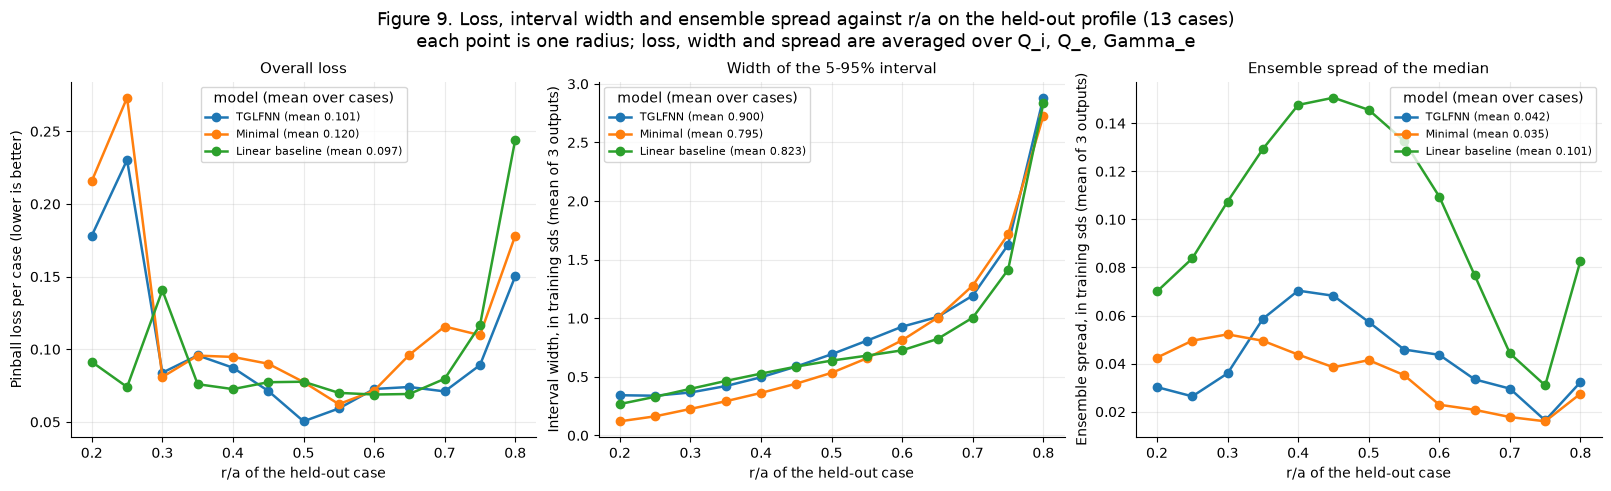

In [216]:
# overall loss, interval width and ensemble spread against r/a on the held-out profile, one line per model
# loss: per-case pinball loss averaged over the 3 outputs and 3 quantiles, on the standardized log targets the models are trained on
# width and spread: divided by the training sd of each output, then averaged over the 3 outputs
def per_case_pinball(split):
    s = SPLITS[split]
    pred = s["bands"].copy()
    pred[:, :2, :] = np.log(pred[:, :2, :])                        # back to the log scale of the heat fluxes
    pred = (pred - y_mean.reshape(1, 3, 1)) / y_std.reshape(1, 3, 1)
    y = s["y_true"].copy()
    y[:, :2] = np.log(y[:, :2])
    y = (y - y_mean) / y_std
    q = np.asarray(QUANTILES).reshape(1, 1, -1)
    err = y[:, :, None] - pred
    return np.maximum(q * err, (q - 1) * err).mean(axis=(1, 2))

r_over_a = X_p2_df["r_over_a"].to_numpy()
order = np.argsort(r_over_a)
panels = [
    ("Pinball loss per case (lower is better)", "Overall loss", lambda sp: per_case_pinball(sp)),
    ("Interval width, in training sds (mean of 3 outputs)", "Width of the 5-95% interval", lambda sp: (SPLITS[sp]["width"] / train_sd).mean(axis=1)),
    ("Ensemble spread, in training sds (mean of 3 outputs)", "Ensemble spread of the median", lambda sp: (SPLITS[sp]["spread"] / train_sd).mean(axis=1)),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ax, (ylabel, title, fn) in zip(axes, panels):
    for m in MODEL_KEYS:
        v = fn(f"{m}_profile2")
        ax.plot(r_over_a[order], v[order], color=P2_COLORS[m], marker="o", linewidth=1.8, label=f"{P2_LABELS[m]} (mean {v.mean():.3f})")
    ax.set(xlabel="r/a of the held-out case", ylabel=ylabel, title=title)
    ax.legend(title="model (mean over cases)")
fig.suptitle(f"Figure 9. Loss, interval width and ensemble spread against r/a on the held-out profile ({len(r_over_a)} cases)\n"
             "each point is one radius; loss, width and spread are averaged over Q_i, Q_e, Gamma_e")
plt.show()

## 8. Are the held-out inputs like the training inputs?

A model is only trusted where it has seen similar inputs. This section compares the distribution of each of the six model inputs in the training set with the 13 cases of the held-out profile, to see how much of the poor held-out accuracy in section 7 could come from inputs the models were never trained on.

**Figure 10.** One panel per input, in its original units. The blue histogram is the density of the training rows and the dotted blue lines mark the smallest and largest training value. The red ticks at the bottom are the 13 held-out cases, drawn individually because there are too few for a histogram. A red tick beyond a dotted line is an input value outside the training range. Each panel states how many of the 13 cases fall outside.

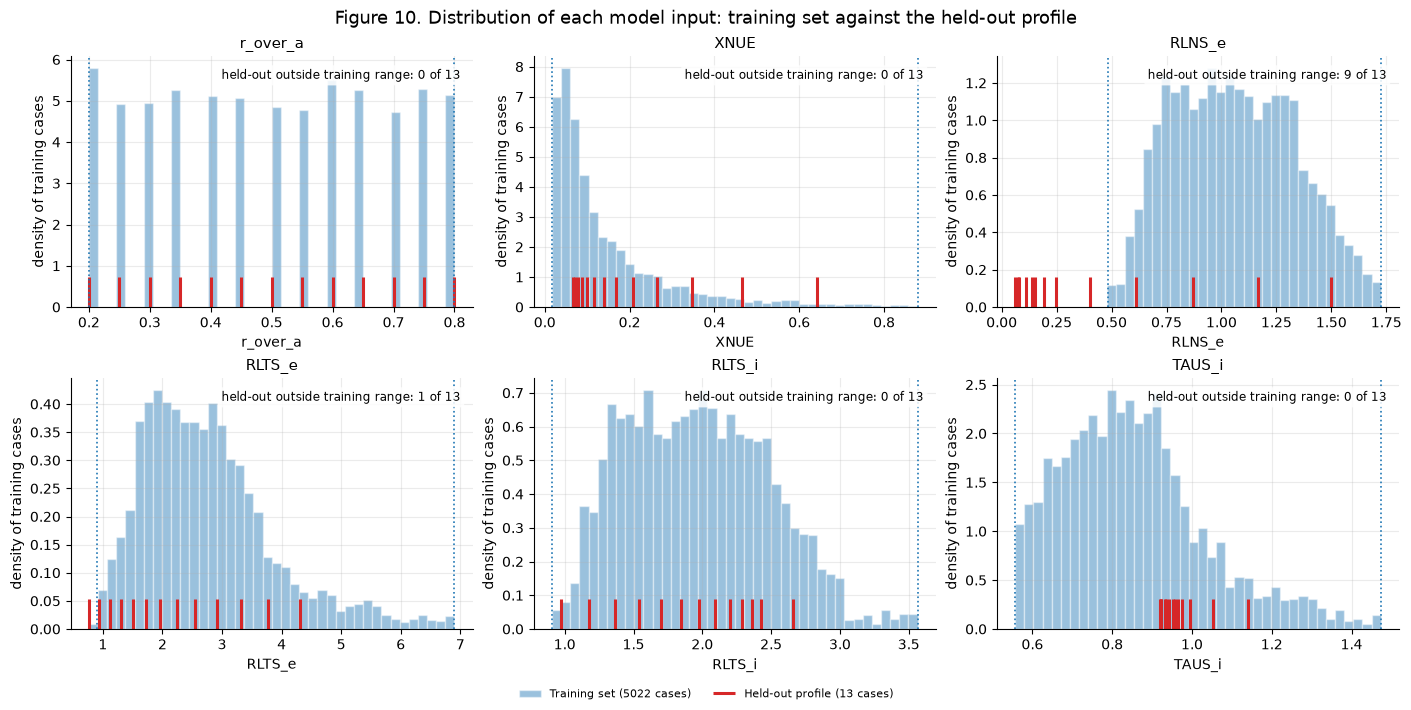

In [217]:
# Figure 10: input distributions, training set vs held-out profile (original units)
# filled steps = density of the training rows; ticks at the bottom = the held-out cases (only 13, so drawn as individual marks, not a histogram)
# dotted lines = range of the training set; held-out cases beyond them are outside what the models were trained on
fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for ax, feat in zip(axes.flat, train_X_df.columns):
    train_vals, held_vals = train_X_df[feat].to_numpy(), X_p2_df[feat].to_numpy()
    lo, hi = min(train_vals.min(), held_vals.min()), max(train_vals.max(), held_vals.max())
    ax.hist(train_vals, bins=np.linspace(lo, hi, 41), density=True, color="tab:blue", alpha=0.45, edgecolor="white", label=f"Training set ({len(train_vals)} cases)")
    ymax = ax.get_ylim()[1]
    ax.vlines(held_vals, 0, 0.12 * ymax, color="tab:red", linewidth=2.2, label=f"Held-out profile ({len(held_vals)} cases)")
    for edge in (train_vals.min(), train_vals.max()):
        ax.axvline(edge, color="tab:blue", linestyle=":", linewidth=1.2)
    outside = int(((held_vals < train_vals.min()) | (held_vals > train_vals.max())).sum())
    ax.text(0.97, 0.95, f"held-out outside training range: {outside} of {len(held_vals)}", transform=ax.transAxes, ha="right", va="top", fontsize=8.5,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="none"))
    ax.set(xlabel=feat, ylabel="density of training cases", title=feat)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Figure 10. Distribution of each model input: training set against the held-out profile")
plt.show()

## 9. Retraining on the new database (`d3d_mydb_101`)

Section 7 showed that the models trained on the two team databases fail on the held-out profile, and section 8 traced much of that to inputs outside the training range (above all `RLNS_e`). `data/d3d_mydb_101_table.csv` was made to fix this: 8000 new TGLF cases (615 or 616 at each of the 13 radii) built by `provided_tools/make_db.py` with seed 101. Compared with the task-sheet recipe, the factor ranges are wider (so that the values of the second profile are reachable at every radius), and the safety factor $q$ (`Q_LOC`) and the magnetic shear $s$ (`Q_PRIME_LOC` $= s\,(q/r)^2$) are varied as well.

This section repeats the pipeline on the new database **alone** (the team databases are not mixed in), then checks whether the held-out profile is predicted better. Everything is a copy of an earlier step with a new name ending in `_n`, so nothing from sections 2 to 8 is overwritten.

1. Load and preprocess (the same steps as step 2, fitted on the new data): the table is put on the team-database schema, split 70 / 15 / 15 by case, invalid rows (`Q_i` or `Q_e` $\le 0$) are dropped, then correlated and low-variance features are removed and the rest is standardized.
2. Train the same three ensembles (`TGLFNN`, minimal, linear baseline) with the same seeds and hyper-parameters.
3. Redo Figures 2 and 3 on the new validation and test sets (Figures 11 and 12).
4. Score the held-out profile again and compare with section 7 (Table 5 and Figures 13 to 15).

The new input set has more features than the six of section 2, because $q$ and $s$ now vary.

In [218]:
# section 9, step 1: load the new database (d3d_mydb_101) and preprocess it like step 2, fitted on this data only
NEW_CSV = DATA_DIR / "d3d_mydb_101_table.csv"

df_n = pd.read_csv(NEW_CSV)
df_n = df_n.rename(columns=lambda c: c[:-2] + "_e" if c.endswith("_1") else c[:-2] + "_i" if c.endswith("_2") else c)   # species 1 / 2 -> e / i
df_n = df_n.rename(columns={"energy_flux_e": "Q_e", "energy_flux_i": "Q_i", "particle_flux_e": "Gamma_e"})           # same target mapping as the team databases
df_n["r_over_a"] = df_n["RMIN_LOC"]
df_n["case"] = "s101_" + df_n["case"].astype(str)                       # ids that cannot clash with the team databases
df_n = df_n[[c for c in df.columns if c in df_n.columns]]               # the columns the team databases have (drops the other fluxes: they must not be inputs)
assert all(c in df_n.columns for c in ["Q_LOC", "Q_PRIME_LOC"] + OUTPUT_COLS)
print(f"new database: {len(df_n)} cases, {df_n.shape[1]} columns")

# step 2.0: split 70 / 15 / 15 by case (here every row is its own case)
cases_n = np.asarray(df_n["case"].unique(), dtype=object)
tv_cases_n, te_cases_n = train_test_split(cases_n, test_size=0.15, random_state=RANDOM_STATE, shuffle=True)
tr_cases_n, va_cases_n = train_test_split(tv_cases_n, test_size=0.1765, random_state=RANDOM_STATE, shuffle=True)
part_n = {k: df_n[df_n["case"].isin(s)] for k, s in (("train", tr_cases_n), ("val", va_cases_n), ("test", te_cases_n))}

# steps 2.1 - 2.3: inputs / targets, encode (drops META_COLS), drop invalid rows
X_n = {k: encode_categoricals(p.drop(columns=ALL_FLUX_COLS))[0] for k, p in part_n.items()}
y_n = {k: p[OUTPUT_COLS] for k, p in part_n.items()}
for k in X_n:
    ok = valid_rows(X_n[k], y_n[k])
    print(f"{k}: dropping {(~ok).sum()} invalid rows of {len(ok)}")
    X_n[k], y_n[k] = X_n[k][ok], y_n[k][ok]

# step 2.4: drop correlated features (|r| > 0.9, training set)
corr_n = X_n["train"].corr().abs()
upper_n = corr_n.where(np.triu(np.ones(corr_n.shape), k=1).astype(bool))
drop_corr_n = [c for c in upper_n.columns if any(upper_n[c] > 0.9)]
X_n = {k: x.drop(columns=drop_corr_n) for k, x in X_n.items()}

# step 2.5: drop low-variance features (min-max variance < 0.01, training set)
range_n = X_n["train"].max() - X_n["train"].min()
minmax_var_n = ((X_n["train"] - X_n["train"].min()) / range_n.replace(0, np.nan)).var().fillna(0)
drop_var_n = minmax_var_n.index[minmax_var_n < 0.01].tolist()
X_n = {k: x.drop(columns=drop_var_n) for k, x in X_n.items()}

# step 2.6: standardize with the training statistics; step 2.7: log heat fluxes
Xs_tr, Xs_va, Xs_te, scaler_n = scale_features(X_n["train"], X_n["val"], X_n["test"])
Xs_n = {"train": Xs_tr, "val": Xs_va, "test": Xs_te}
ylog_n = {k: log_targets(y) for k, y in y_n.items()}
y_mean_n, y_std_n = ylog_n["train"].values.mean(axis=0), ylog_n["train"].values.std(axis=0)
train_sd_n = y_n["train"].std().to_numpy()                 # training sd of each flux in flux units, the new counterpart of train_sd
INPUT_DIM_N = Xs_n["train"].shape[1]

print(f"\nrows: train {len(Xs_n['train'])}, validation {len(Xs_n['val'])}, test {len(Xs_n['test'])}")
print(f"{INPUT_DIM_N} model inputs (section 2 had {INPUT_DIM}): {list(Xs_n['train'].columns)}")
print("new in this section:", [c for c in Xs_n["train"].columns if c not in train_X_df.columns])

new database: 8000 cases, 30 columns
train: dropping 612 invalid rows of 5599
val: dropping 137 invalid rows of 1201
test: dropping 129 invalid rows of 1200

rows: train 4987, validation 1064, test 1071
8 model inputs (section 2 had 6): ['r_over_a', 'XNUE', 'RLNS_e', 'RLTS_e', 'RLTS_i', 'TAUS_i', 'Q_LOC', 'Q_PRIME_LOC']
new in this section: ['Q_LOC', 'Q_PRIME_LOC']


Train the three ensembles on the new training split, with the same five seeds, 150 epochs and learning rates as step 4. The networks are sized for the new number of inputs (the class defaults are the six of section 2, so `input_dim` is passed explicitly).

In [219]:
# section 9, step 2: train the three ensembles on the new data (same seeds and hyper-parameters as step 4)
MODELS_N = ("tglfnn", "minimal", "linear")
Xtr_t = to_tensor(Xs_n["train"].values)
ytr_t = to_tensor((ylog_n["train"].values - y_mean_n) / y_std_n)

def fit_ensemble_n(member_cls, ensemble_cls):
    """Like fit_ensemble, but the members get INPUT_DIM_N inputs and are trained on the new data."""
    results = [fit_member(lambda: member_cls(input_dim=INPUT_DIM_N), seed, X_train=Xtr_t, y_train=ytr_t) for seed in SEEDS]
    ens = ensemble_cls(num_models=len(SEEDS), seeds=SEEDS)
    ens.models = nn.ModuleList([r[0] for r in results])
    return ens, [r[1] for r in results]

ENSEMBLES_N, EPOCH_LOSSES_N = {}, {}
for key, (cls, ens_cls) in {"tglfnn": (TGLFNN, TGLFNNEnsemble), "minimal": (TGLFNNMinimalHidden, TGLFNNMinimalHiddenEnsemble),
                            "linear": (TGLFLinear, TGLFLinearEnsemble)}.items():
    t0 = time.time()
    ENSEMBLES_N[key], EPOCH_LOSSES_N[key] = fit_ensemble_n(cls, ens_cls)
    print(f"{key}: final training loss {np.mean([l[-1] for l in EPOCH_LOSSES_N[key]]):.3f} ({time.time() - t0:.0f} s)")

tglfnn: final training loss 0.072 (10 s)
minimal: final training loss 0.075 (7 s)
linear: final training loss 0.141 (4 s)


**Table 4.** The new validation and test sets scored like Table 1: accuracy of the median prediction and coverage of the 5-95% interval (nominal coverage 0.90). Width, spread and nRMSE are in training standard deviations of the **new** training set.

In [220]:
def predict_n(ensemble, X):
    """Like predict_ensemble, but with the target mean and sd of the new training set."""
    ensemble.eval()
    with torch.no_grad():
        members = sorted_quantiles(ensemble.member_outputs(to_tensor(X.values))).numpy()   # (member, case, target, quantile), standardized
    members = members * y_std_n.reshape(1, 1, 3, 1) + y_mean_n.reshape(1, 1, 3, 1)
    spread = members[..., 1].std(axis=0)
    bands = members.mean(axis=0)
    bands[:, :2, :] = np.exp(bands[:, :2, :])                                               # heat fluxes: undo the natural log
    return bands, spread, bands[..., 2] - bands[..., 0]

SPLITS_N = {}
for name, k in (("validation", "val"), ("test", "test")):
    Xs, y = Xs_n[k], y_n[k]
    for m in MODELS_N:
        bands, spread, width = predict_n(ENSEMBLES_N[m], Xs)
        SPLITS_N[f"{m}_{name}"] = {"bands": bands, "spread": spread, "width": width, "y_true": y.values, "X": X_n[k]}

def evaluate_n(store, split, sd):
    """Same metrics as evaluate; sd = the training sd of each flux used to normalize nRMSE, spread and width."""
    bands, y = store[split]["bands"], store[split]["y_true"]
    rows = []
    for t, key in enumerate(TARGET_KEYS):
        median, true = bands[:, t, 1], y[:, t]
        sse = np.sum((median - true) ** 2)
        rows.append({
            "split": split, "target": key,
            "R2 (median)": 1 - sse / np.sum((true - true.mean()) ** 2),
            "nRMSE (median)": np.sqrt(sse / len(true)) / sd[t],
            "spread (median)": store[split]["spread"][:, t].mean() / sd[t],
            "width (median)": store[split]["width"][:, t].mean() / sd[t],
            "coverage (5-95%)": np.mean((true >= bands[:, t, 0]) & (true <= bands[:, t, 2])),
        })
    return pd.DataFrame(rows)

print("Table 4. Accuracy of the median prediction and coverage of the 5-95% interval, models trained on the new database (nominal coverage 0.90)")
table_4 = pd.concat([evaluate_n(SPLITS_N, s, train_sd_n) for s in SPLITS_N], ignore_index=True).round(3)
table_4

Table 4. Accuracy of the median prediction and coverage of the 5-95% interval, models trained on the new database (nominal coverage 0.90)


,split,target,R2 (median),nRMSE (median),spread (median),width (median),coverage (5-95%)
0,tglfnn_validation,Q_i,0.865,0.358,0.010,1.360,0.930
1,tglfnn_validation,Q_e,0.653,0.440,0.002,0.801,0.930
2,tglfnn_validation,Gamma_e,0.770,0.372,0.059,1.006,0.958
3,minimal_validation,Q_i,0.824,0.409,0.007,1.049,0.928
4,minimal_validation,Q_e,-0.252,0.835,0.001,0.480,0.931
5,minimal_validation,Gamma_e,0.687,0.434,0.046,0.987,0.940
6,linear_validation,Q_i,0.458,0.719,0.018,0.574,0.535
7,linear_validation,Q_e,0.116,0.701,0.004,0.416,0.711
8,linear_validation,Gamma_e,0.357,0.622,0.045,0.770,0.808
9,tglfnn_test,Q_i,0.848,0.358,0.009,1.350,0.937


**Figure 11.** Figure 2 again, for the models trained on the new database: every Table 4 metric by target, for all three models on the new validation and test sets (solid = validation, hatched = test). Width and spread are divided by the training standard deviation of the target, so the targets can be compared. The dashed line in the coverage panel is the nominal 0.90.

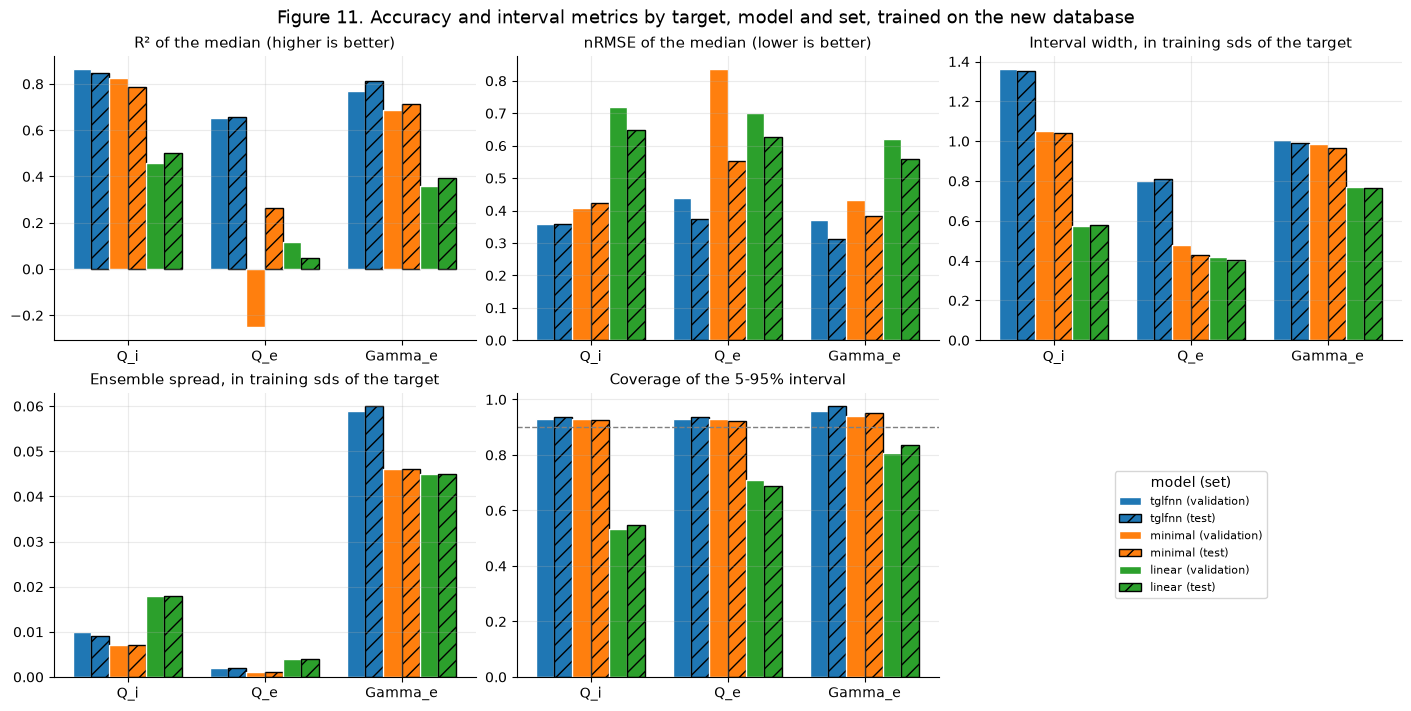

In [221]:
# Figure 11: Table 4 metrics as grouped bars (the Figure 2 layout). x = target, one bar per (model, split).
bars_n = table_4.copy()
bars_n["model"] = bars_n["split"].str.split("_").str[0]
bars_n["set"] = bars_n["split"].str.split("_").str[1]
METRICS_N = [
    ("R2 (median)", "R² of the median (higher is better)"),
    ("nRMSE (median)", "nRMSE of the median (lower is better)"),
    ("width (median)", "Interval width, in training sds of the target"),
    ("spread (median)", "Ensemble spread, in training sds of the target"),
    ("coverage (5-95%)", "Coverage of the 5-95% interval"),
]
MODEL_COLORS_N = {"tglfnn": "tab:blue", "minimal": "tab:orange", "linear": "tab:green"}
groups_n = [(m, s) for m in MODEL_COLORS_N for s in ("validation", "test")]
bw = 0.8 / len(groups_n)
xt = np.arange(len(TARGET_KEYS))

fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for ax, (col, title) in zip(axes.flat, METRICS_N):
    for i, (model, split) in enumerate(groups_n):
        sub = bars_n[(bars_n["model"] == model) & (bars_n["set"] == split)].set_index("target").loc[TARGET_KEYS]
        ax.bar(xt + (i - (len(groups_n) - 1) / 2) * bw, sub[col], bw, color=MODEL_COLORS_N[model],
               hatch="//" if split == "test" else None, edgecolor="white" if split == "validation" else "black",
               label=f"{model} ({split})")
    if col == "coverage (5-95%)":
        ax.axhline(0.9, color="gray", linestyle="--", linewidth=1)
    ax.set(title=title, xticks=xt, xticklabels=TARGET_KEYS)
for ax in axes.flat[len(METRICS_N):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", title="model (set)")
fig.suptitle(fig_title(11, "Accuracy and interval metrics by target, model and set, trained on the new database"))
plt.show()

**Figure 12.** Figure 3 again, for the models trained on the new database: log-ratio plots for all three ensembles on the new validation and test sets. Each boxed row is one model and set; columns are targets. For $Q_i$ and $Q_e$ the y axis is $\log_{10}(\hat{y}/y)$, the median prediction over the true flux, so 0 is a perfect prediction and +1 is a factor of 10 too high. Points are single cases. The black line is the median log-ratio within equal-count bins of the true flux, and the shaded band is the median 5-95% interval in the same bin. Each panel gives the R² of the median and the fraction of cases whose true value falls inside the interval. $\Gamma_e$ can be zero or negative, so its column shows $(\hat{y}-y)/\sigma_\mathrm{train}$ instead, with $\sigma_\mathrm{train}$ from the new training set.

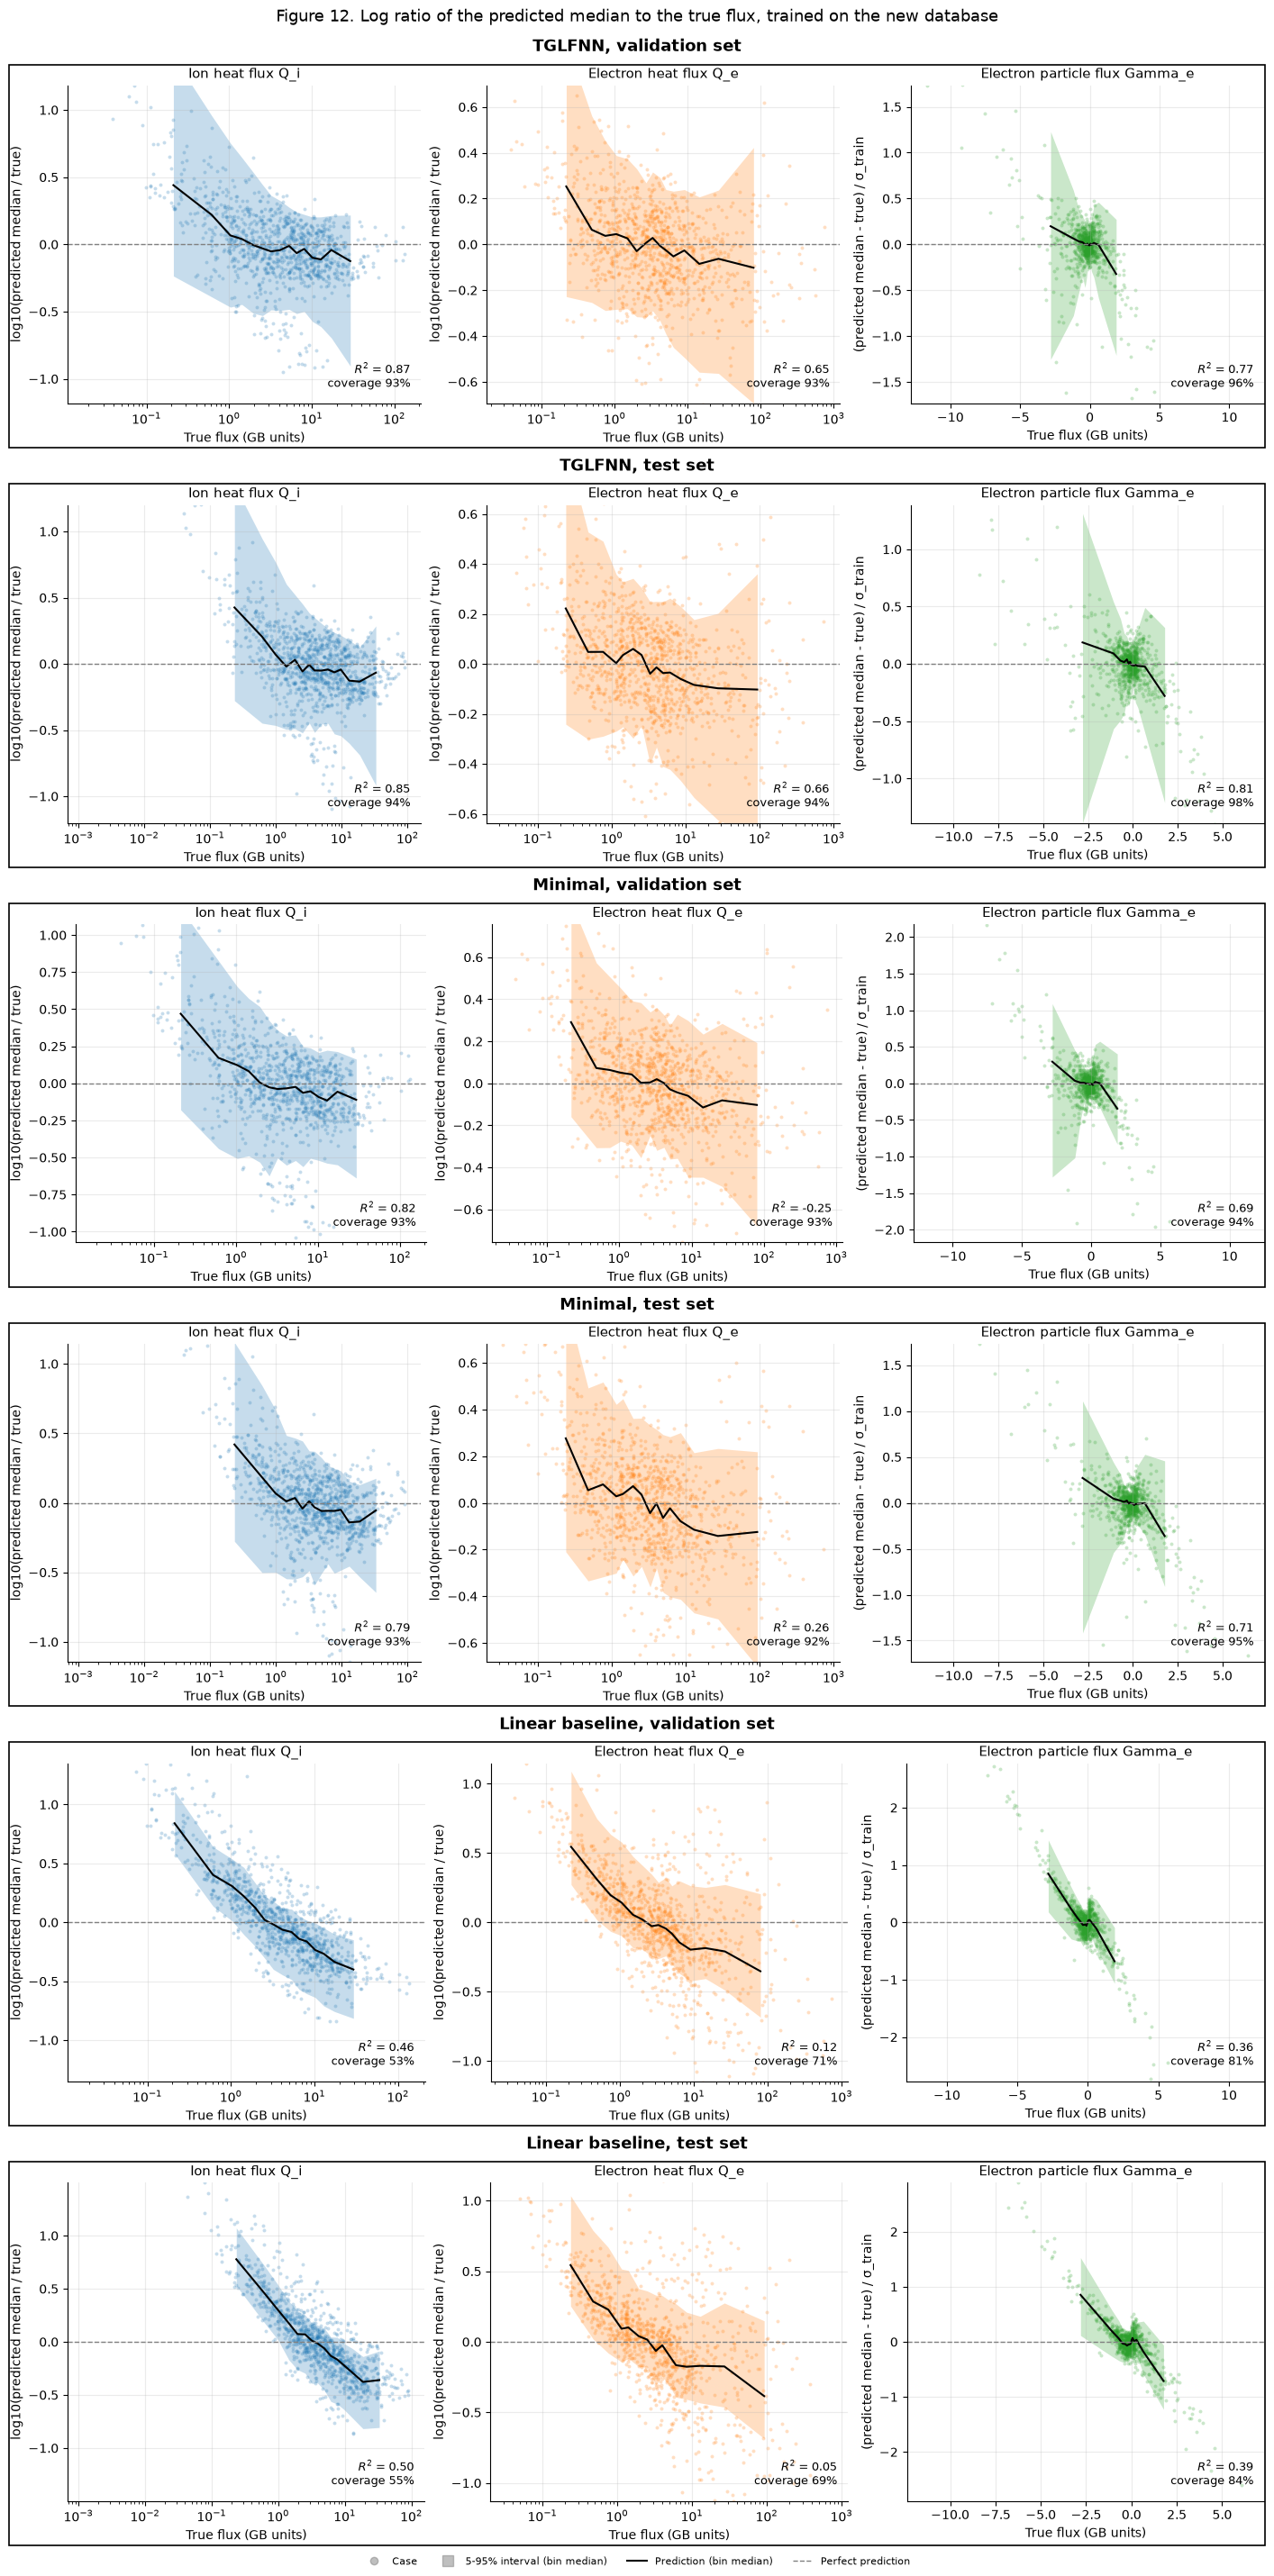

In [222]:
from matplotlib.lines import Line2D

# Figure 12: the Figure 3 layout, new models and new validation / test sets. Rows = (model, set), columns = target.
N_BINS_N = 15
ROWS_N = [(m, s) for m in MODELS_N for s in ("validation", "test")]
MODEL_LABEL_N = {"tglfnn": "TGLFNN", "minimal": "Minimal", "linear": "Linear baseline"}

fig = plt.figure(figsize=(14, 28.5), constrained_layout=True)
strips = fig.subfigures(2 * len(ROWS_N), 1, height_ratios=[0.09, 1] * len(ROWS_N), hspace=0.0)
axes = []
for r, (model, split) in enumerate(ROWS_N):
    title_strip, row_fig = strips[2 * r], strips[2 * r + 1]
    title_strip.text(0.5, 0.25, f"{MODEL_LABEL_N[model]}, {split} set", ha="center", va="bottom", fontsize=13, fontweight="bold")
    row_fig.add_artist(plt.Rectangle((0.002, 0.002), 0.996, 0.996, transform=row_fig.transSubfigure, fill=False, edgecolor="black", linewidth=1.2))
    axes.append(row_fig.subplots(1, 3))
axes = np.array(axes)
for r, (model, split) in enumerate(ROWS_N):
    bands, y = SPLITS_N[f"{model}_{split}"]["bands"], SPLITS_N[f"{model}_{split}"]["y_true"]
    for t, ax in enumerate(axes[r]):
        true = y[:, t]
        low, med, high = bands[:, t, 0], bands[:, t, 1], bands[:, t, 2]
        inside = np.mean((true >= low) & (true <= high))
        r2 = 1 - np.sum((med - true) ** 2) / np.sum((true - true.mean()) ** 2)
        if LOG_FLUX_AXIS[t]:
            l_med, l_low, l_high = (np.log10(v / true) for v in (med, low, high))
        else:
            l_med, l_low, l_high = ((v - true) / train_sd_n[t] for v in (med, low, high))
        chunks = np.array_split(np.argsort(true), N_BINS_N)
        bx = np.array([np.median(true[c]) for c in chunks])
        b_med, b_low, b_high = (np.array([np.median(v[c]) for c in chunks]) for v in (l_med, l_low, l_high))
        ax.scatter(true, l_med, s=8, alpha=0.25, color=TARGET_COLORS[t], linewidths=0, rasterized=True, label="Case")
        ax.fill_between(bx, b_low, b_high, color=TARGET_COLORS[t], alpha=0.25, linewidth=0, label="5-95% interval (bin median)")
        ax.plot(bx, b_med, color="black", linewidth=1.5, label="Prediction (bin median)")
        ax.axhline(0, color="gray", linestyle="--", linewidth=1, label="Perfect prediction")
        if LOG_FLUX_AXIS[t]:
            ax.set_xscale("log")
        lim = np.percentile(np.abs(np.concatenate([l_med, b_low, b_high])), 99)
        ax.set_ylim(-lim, lim)
        ax.text(0.97, 0.04, f"$R^2$ = {r2:.2f}\ncoverage {inside:.0%}", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
        ax.set_title(TARGET_NAMES[t])
        ax.set_xlabel("True flux (GB units)")
        ax.set_ylabel("log10(predicted median / true)" if LOG_FLUX_AXIS[t] else "(predicted median - true) / σ_train")

handles, labels = axes[0, 0].get_legend_handles_labels()
swatch = {"Case": "o", "5-95% interval (bin median)": "s"}
handles = [Line2D([], [], marker=swatch[l], linestyle="", color="gray", alpha=0.5, markersize=6 if l == "Case" else 9)
           if l in swatch else h for h, l in zip(handles, labels)]
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False, markerscale=1)
fig.suptitle(fig_title(12, "Log ratio of the predicted median to the true flux, trained on the new database", note=f"{N_BINS_N} equal-count bins"))
plt.show()

### Held-out profile: original against new training data

The held-out profile is the same 13 cases as in section 7 (`raw` and `X_p2_df`), now scaled with the scaler of the new training set and passed to the models trained on the new database.

To compare the two sets of models fairly, both are scored with the **same yardstick**: nRMSE, width and spread are divided by the training standard deviations of the *original* training set (`train_sd`), not each model's own. The cell also counts the held-out cases outside the new training range, per input, to see whether the new database closes the gaps found in section 8.

**Table 5.** Held-out metrics for the models trained on the original data (section 7, Table 3) and on the new database, side by side. The last column of each metric is the new value.

In [223]:
# held-out profile (section 7) scored by the models trained on the new database
cols_n = list(Xs_n["train"].columns)
missing = [c for c in cols_n if c not in raw.columns]
assert not missing, f"held-out table lacks model inputs: {missing}"
X_p2n_df = raw.loc[X_p2_df.index, cols_n]                      # same 13 cases as section 7, the columns the new models use
y_p2n_df = raw.loc[X_p2_df.index, OUTPUT_COLS]
assert valid_rows(X_p2n_df, y_p2n_df).all()

X_p2n_scaled = X_p2n_df.copy()
cont_n = list(scaler_n.feature_names_in_)
X_p2n_scaled[cont_n] = scaler_n.transform(X_p2n_df[cont_n])    # new training mean / sd, nothing refit

# held-out cases outside the training range, per input, for the original and the new training set
out_old = ((X_p2_df < train_X_df.min()) | (X_p2_df > train_X_df.max())).sum()
out_new = ((X_p2n_df < X_n["train"].min()) | (X_p2n_df > X_n["train"].max())).sum()
print("held-out cases outside the training range (of 13), original -> new training set:")
for c in cols_n:
    print(f"  {c:12s} {int(out_old[c]) if c in out_old.index else '-':>2} -> {int(out_new[c])}")

for m in MODELS_N:
    bands, spread, width = predict_n(ENSEMBLES_N[m], X_p2n_scaled)
    SPLITS_N[f"{m}_profile2"] = {"bands": bands, "spread": spread, "width": width, "y_true": y_p2n_df.values, "X": X_p2n_df}

table_p2_new = pd.concat([evaluate_n(SPLITS_N, f"{m}_profile2", train_sd) for m in MODELS_N], ignore_index=True).round(3)   # yardstick: original train_sd
table_5 = table_p2.merge(table_p2_new, on=["split", "target"], suffixes=(" orig", " new"))
keep_cols = ["split", "target"] + [f"{k} {v}" for k in ("R2 (median)", "nRMSE (median)", "width (median)", "coverage (5-95%)") for v in ("orig", "new")]
print("\nTable 5. Held-out profile: models trained on the original data (orig) against the new database (new), same yardstick")
table_5[keep_cols]

held-out cases outside the training range (of 13), original -> new training set:
  r_over_a      0 -> 0
  XNUE          0 -> 0
  RLNS_e        9 -> 0
  RLTS_e        1 -> 0
  RLTS_i        0 -> 0
  TAUS_i        0 -> 0
  Q_LOC         - -> 0
  Q_PRIME_LOC   - -> 0

Table 5. Held-out profile: models trained on the original data (orig) against the new database (new), same yardstick


,split,target,R2 (median) orig,R2 (median) new,nRMSE (median) orig,nRMSE (median) new,width (median) orig,width (median) new,coverage (5-95%) orig,coverage (5-95%) new
0,tglfnn_profile2,Q_i,-0.989,0.601,0.437,0.196,0.944,0.745,0.923,0.923
1,tglfnn_profile2,Q_e,-1.754,0.685,0.190,0.064,0.401,0.179,1.000,1.000
2,tglfnn_profile2,Gamma_e,-1.405,0.576,0.287,0.120,1.354,0.856,1.000,1.000
3,minimal_profile2,Q_i,-0.813,0.489,0.417,0.221,0.752,0.686,0.769,0.846
4,minimal_profile2,Q_e,-1.997,0.320,0.199,0.095,0.380,0.240,0.615,1.000
5,minimal_profile2,Gamma_e,-3.114,0.810,0.375,0.081,1.254,1.070,0.692,1.000
6,linear_profile2,Q_i,-0.879,0.714,0.424,0.166,0.668,0.391,0.846,0.615
7,linear_profile2,Q_e,-34.393,-2.187,0.683,0.205,0.603,0.434,0.615,0.615
8,linear_profile2,Gamma_e,-2.399,-0.052,0.341,0.190,1.198,0.900,1.000,0.923


**Figures 13 and 14.** The held-out versions of Figures 2 and 3 (Figures 2c and 3c), with the models trained on the original data next to the models trained on the new database.

Figure 13 shows every Table 5 metric by output and model: the pale hatched bar is the original training data, the solid bar the new database. Width and spread are in training standard deviations of the original set (the common yardstick) and the dashed line in the coverage panel is the nominal 0.90.

Figure 14 plots $\log_{10}(\hat{y}/y)$, the predicted median over the true flux, for $Q_i$ and $Q_e$, and $(\hat{y} - y)/\sigma_\mathrm{train}$ for $\Gamma_e$; 0 is a perfect prediction. Each case appears twice, side by side: gray = original training data, colored = new database, with the 5-95% interval as the vertical bar. Each panel gives the R² and coverage of both. Closer to the dashed zero line and shorter bars that still reach it mean a better model.

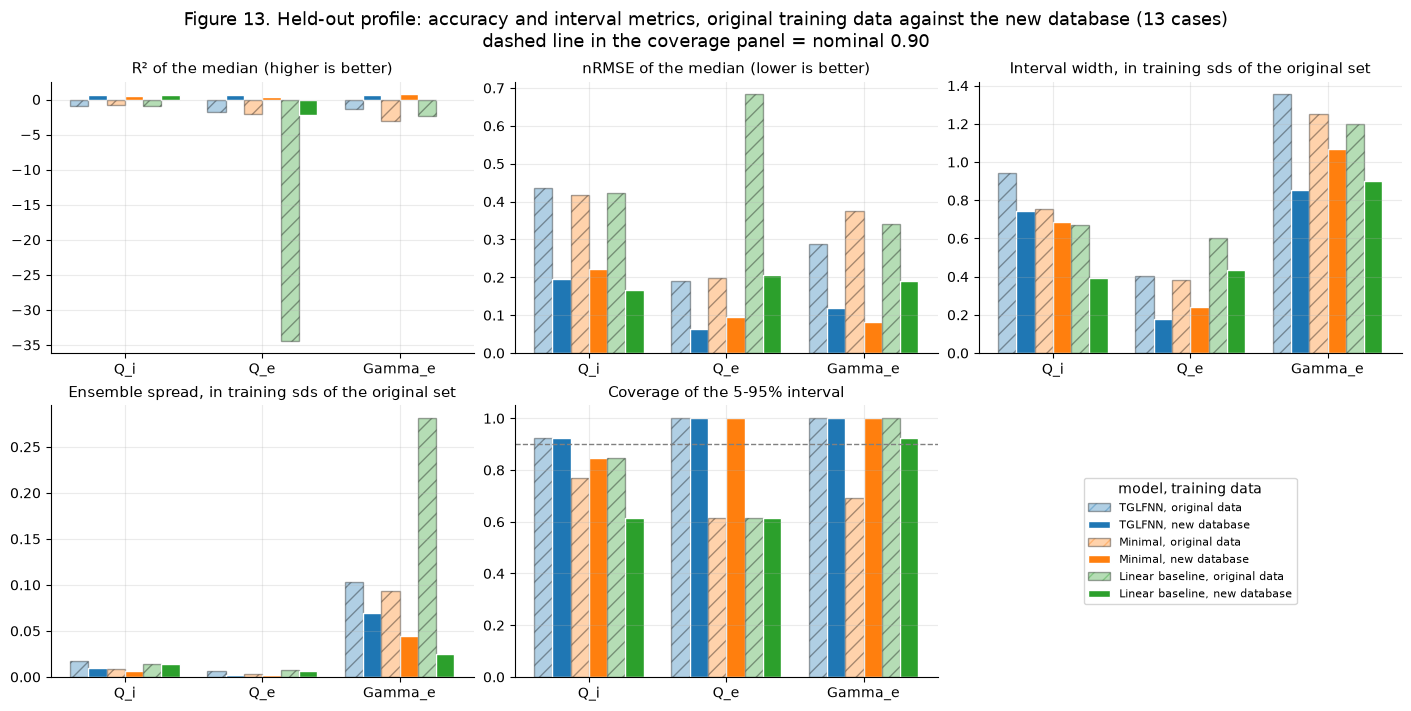

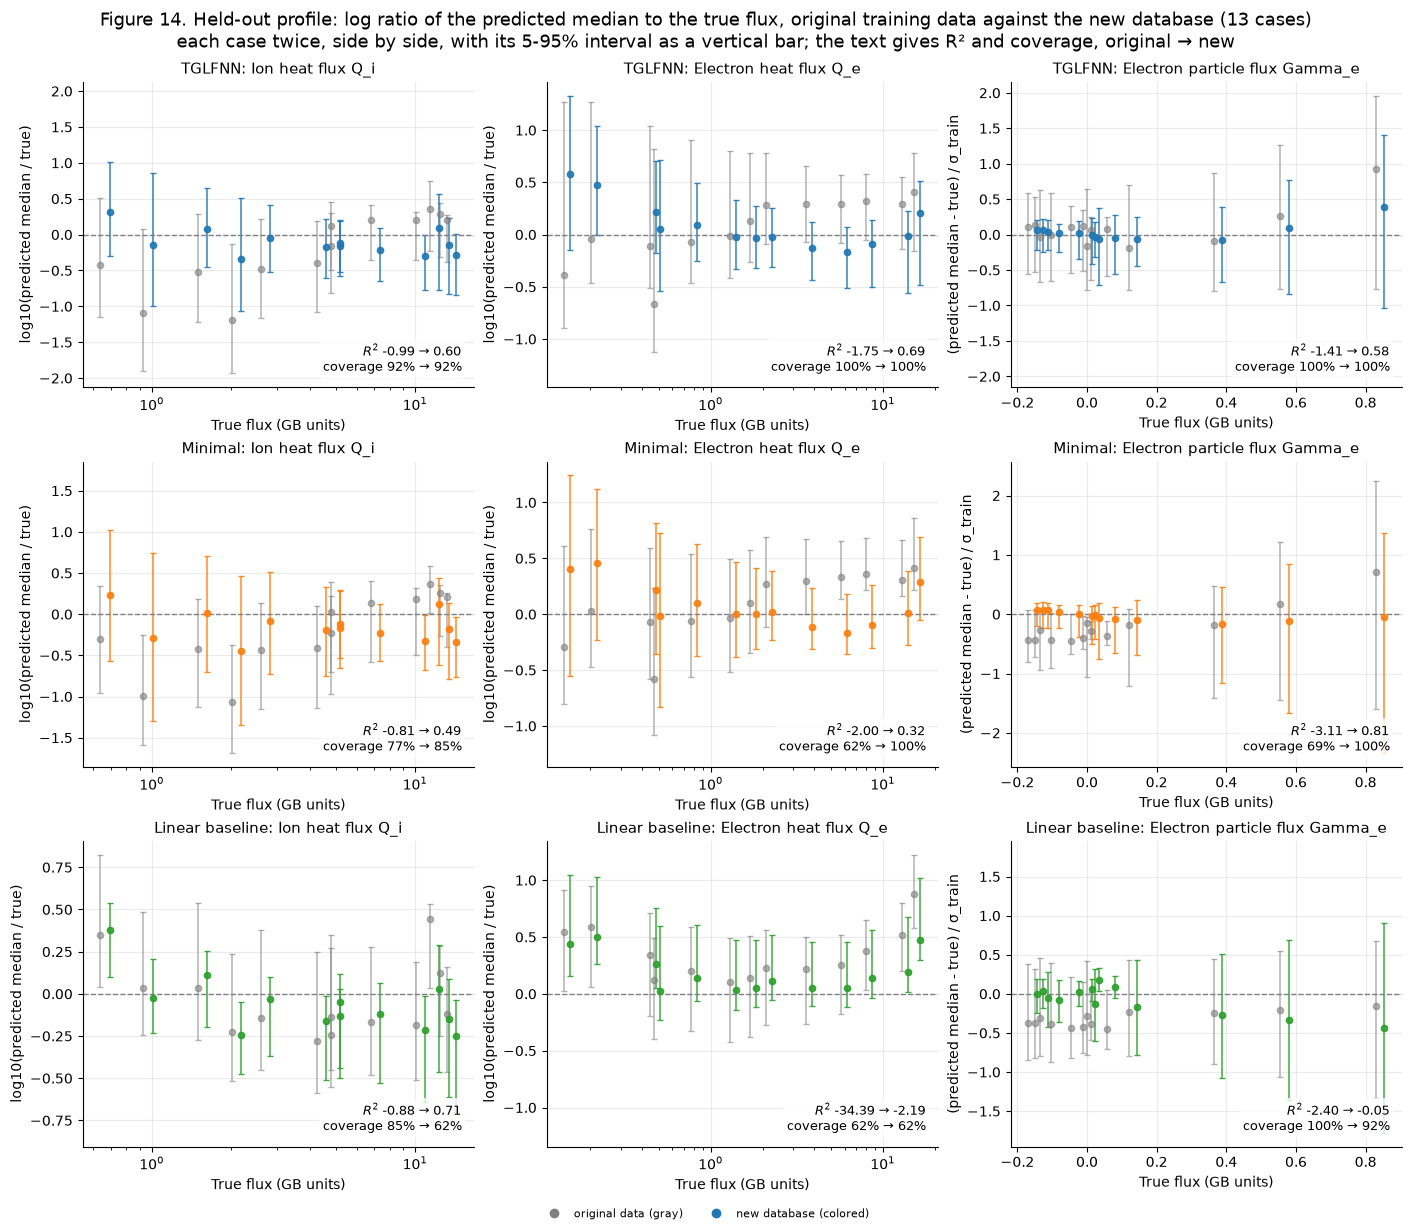

In [224]:
# Figures 13 and 14: the held-out versions of Figures 2 and 3, original training data against the new database
LABEL_N = {"tglfnn": "TGLFNN", "minimal": "Minimal", "linear": "Linear baseline"}
COLOR_N = {"tglfnn": "tab:blue", "minimal": "tab:orange", "linear": "tab:green"}
n_p2n = len(y_p2n_df)

from matplotlib.lines import Line2D

# ---- Figure 13: metrics by target and model, original (pale, hatched) vs new (solid)
tab = {"orig": table_p2.assign(model=table_p2["split"].str.split("_").str[0]), "new": table_p2_new.assign(model=table_p2_new["split"].str.split("_").str[0])}
METRICS_P = [
    ("R2 (median)", "R² of the median (higher is better)"),
    ("nRMSE (median)", "nRMSE of the median (lower is better)"),
    ("width (median)", "Interval width, in training sds of the original set"),
    ("spread (median)", "Ensemble spread, in training sds of the original set"),
    ("coverage (5-95%)", "Coverage of the 5-95% interval"),
]
combos = [(m, v) for m in MODELS_N for v in ("orig", "new")]
bwp = 0.8 / len(combos)
xt = np.arange(len(TARGET_KEYS))
fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for ax, (col, title) in zip(axes.flat, METRICS_P):
    for i, (m, v) in enumerate(combos):
        sub = tab[v][tab[v]["model"] == m].set_index("target").loc[TARGET_KEYS]
        ax.bar(xt + (i - (len(combos) - 1) / 2) * bwp, sub[col], bwp, color=COLOR_N[m], alpha=0.35 if v == "orig" else 1.0,
               hatch="//" if v == "orig" else None, edgecolor="black" if v == "orig" else "white")
    if col == "coverage (5-95%)":
        ax.axhline(0.9, color="gray", linestyle="--", linewidth=1)
    ax.set(title=title, xticks=xt, xticklabels=TARGET_KEYS)
for ax in axes.flat[len(METRICS_P):]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR_N[m], alpha=0.35 if v == "orig" else 1.0, hatch="//" if v == "orig" else None,
                         ec="black" if v == "orig" else "white") for m, v in combos]
axes.flat[-1].legend(handles, [f"{LABEL_N[m]}, {'original data' if v == 'orig' else 'new database'}" for m, v in combos], loc="center", title="model, training data")
fig.suptitle(f"Figure 13. Held-out profile: accuracy and interval metrics, original training data against the new database ({n_p2n} cases)\n"
             "dashed line in the coverage panel = nominal 0.90")
plt.show()

# ---- Figure 14: log10(predicted median / true flux) per case with its 5-95% interval; gray = original data, colored = new database
fig, axes = plt.subplots(len(MODELS_N), 3, figsize=(14, 3.8 * len(MODELS_N) + 0.8), constrained_layout=True, squeeze=False)
for r, m in enumerate(MODELS_N):
    for t, ax in enumerate(axes[r]):
        stats, lims = {}, []
        for v, store, sd_t, color in (("orig", SPLITS, train_sd[t], "gray"), ("new", SPLITS_N, train_sd[t], COLOR_N[m])):
            s = store[f"{m}_profile2"]
            true = s["y_true"][:, t]
            low, med, high = s["bands"][:, t, 0], s["bands"][:, t, 1], s["bands"][:, t, 2]
            if LOG_FLUX_AXIS[t]:
                l_low, l_med, l_high = (np.log10(q / true) for q in (low, med, high))
                xx = true * (0.96 if v == "orig" else 1.04)
            else:
                l_low, l_med, l_high = ((q - true) / sd_t for q in (low, med, high))
                xx = true + (-1 if v == "orig" else 1) * 0.012 * np.ptp(true)
            ax.errorbar(xx, l_med, yerr=[l_med - l_low, l_high - l_med], fmt="o", color=color, ecolor=color, elinewidth=1.1, capsize=2,
                        markersize=4.5, alpha=0.9 if v == "new" else 0.6, label="original data" if v == "orig" else "new database")
            r2 = 1 - np.sum((med - true) ** 2) / np.sum((true - true.mean()) ** 2)
            stats[v] = (r2, np.mean((true >= low) & (true <= high)))
            lims.append(np.max(np.abs(np.concatenate([l_low, l_high]))))
        ax.axhline(0, color="gray", linestyle="--", linewidth=1)
        if LOG_FLUX_AXIS[t]:
            ax.set_xscale("log")
        ax.set_ylim(-1.1 * max(lims), 1.1 * max(lims))
        ax.text(0.97, 0.04, f"$R^2$ {stats['orig'][0]:.2f} → {stats['new'][0]:.2f}\ncoverage {stats['orig'][1]:.0%} → {stats['new'][1]:.0%}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=9, bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="none"))
        ax.set_title(f"{LABEL_N[m]}: {TARGET_NAMES[t]}")
        ax.set_xlabel("True flux (GB units)")
        ax.set_ylabel("log10(predicted median / true)" if LOG_FLUX_AXIS[t] else "(predicted median - true) / σ_train")
fig.legend([Line2D([], [], marker="o", linestyle="", color="gray"), Line2D([], [], marker="o", linestyle="", color="tab:blue")],
           ["original data (gray)", "new database (colored)"], loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"Figure 14. Held-out profile: log ratio of the predicted median to the true flux, original training data against the new database ({n_p2n} cases)\n"
             "each case twice, side by side, with its 5-95% interval as a vertical bar; the text gives R² and coverage, original → new")
plt.show()

**Figure 15.** Figure 9 again with both training sets: loss, interval width and ensemble spread against $r/a$ on the held-out profile, one color per model, dashed pale line = trained on the original data, solid line = trained on the new database. One point per radius. All three quantities use the **original** training set as the common yardstick: the loss is the pinball loss of the case on the targets standardized with the original training mean and sd (averaged over the three outputs and three quantiles), and width and spread are divided by the original training sd of each output. The legend gives each line's mean over the 13 cases.

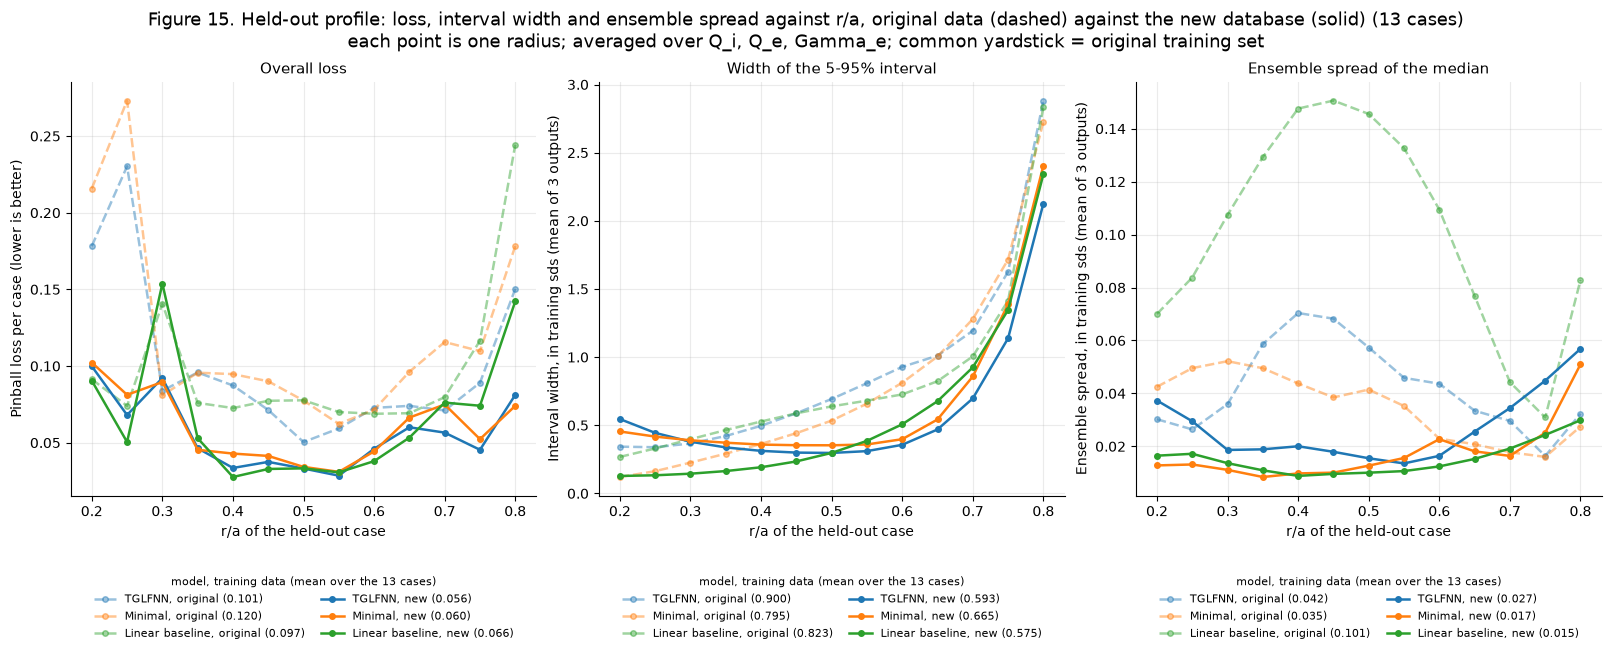

In [226]:
# Figure 15: held-out loss, width and spread against r/a, original data (dashed) vs new database (solid)
# loss: per-case pinball on the log targets standardized with the ORIGINAL training mean / sd (y_mean, y_std), so both sets of models share one scale
def case_pinball(store, split):
    s = store[split]
    pred = s["bands"].copy()
    pred[:, :2, :] = np.log(pred[:, :2, :])
    pred = (pred - y_mean.reshape(1, 3, 1)) / y_std.reshape(1, 3, 1)
    y = s["y_true"].copy()
    y[:, :2] = np.log(y[:, :2])
    y = (y - y_mean) / y_std
    q = np.asarray(QUANTILES).reshape(1, 1, -1)
    err = y[:, :, None] - pred
    return np.maximum(q * err, (q - 1) * err).mean(axis=(1, 2))

ra = X_p2_df["r_over_a"].to_numpy()
order = np.argsort(ra)
panels = [
    ("Pinball loss per case (lower is better)", "Overall loss", lambda st, sp: case_pinball(st, sp)),
    ("Interval width, in training sds (mean of 3 outputs)", "Width of the 5-95% interval", lambda st, sp: (st[sp]["width"] / train_sd).mean(axis=1)),
    ("Ensemble spread, in training sds (mean of 3 outputs)", "Ensemble spread of the median", lambda st, sp: (st[sp]["spread"] / train_sd).mean(axis=1)),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 6.4), constrained_layout=True)
for ax, (ylabel, title, fn) in zip(axes, panels):
    for store, style, alpha, tag in ((SPLITS, "--", 0.45, "original"), (SPLITS_N, "-", 1.0, "new")):   # original first, so it fills the legend's left column
        for m in MODELS_N:
            v = fn(store, f"{m}_profile2")
            ax.plot(ra[order], v[order], color=COLOR_N[m], linestyle=style, alpha=alpha, marker="o", markersize=4, linewidth=1.8,
                    label=f"{LABEL_N[m]}, {tag} ({v.mean():.3f})")
    ax.set(xlabel="r/a of the held-out case", ylabel=ylabel, title=title)
    # legend under the panel, clear of the lines: left column = original data (dashed), right column = new database (solid)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8, frameon=False, columnspacing=1.5,
              title="model, training data (mean over the 13 cases)", title_fontsize=8)
fig.suptitle(f"Figure 15. Held-out profile: loss, interval width and ensemble spread against r/a, original data (dashed) against the new database (solid) ({len(ra)} cases)\n"
             "each point is one radius; averaged over Q_i, Q_e, Gamma_e; common yardstick = original training set")
plt.show()